# Análisis Exploratorio de los Datos · F1 · Grupo 14

Ciencia de Datos · UTN FRM · 2026

Este notebook recorre el dataset de F1 del Grupo 14 siguiendo **las fases de la teórica**,
en el mismo orden: inspección inicial, análisis univariado, análisis bivariado, calidad de
datos, hipótesis y selección final de variables.

El dataset lo genera el pipeline (`include/output/f1_all_full.parquet`): cada fila es
**un piloto en un Gran Premio** (2018–2026). La variable objetivo es `RACE_Position`
(posición final de carrera, de 1 a 22).

Dos reglas que se respetan en todo el notebook:

- El univariado y el bivariado miran **familias completas de columnas**. El bivariado no
  cruza todo contra el objetivo: decide entre las versiones ABS y DBT, muestra qué columnas
  repiten información y arma una lista corta de candidatas.
- Las hipótesis siguen el método de la cátedra: primero la afirmación, después una medida con
  cortes fijados de antemano, como mucho dos movimientos y una decisión por variable.

> El análisis temporal queda fuera de alcance (salvo el chequeo de cobertura por temporada),
> según lo acordado.

Se corre de arriba hacia abajo.

## Sección 1: Inspección inicial del dataset

Antes de calcular nada conviene tener un mapa del dataset: cuántas filas hay, qué mide cada
columna, de qué tipo es y con qué calidad viene.

### Cargar el dataset y preparar las herramientas

El parquet se baja de Drive la primera vez. En la misma celda se definen dos cosas que se usan
en todo el notebook: el estilo de los gráficos y la función `mostrar`, que presenta cada tabla
con título, coma decimal y, cuando corresponde, las zonas del semáforo pintadas.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ARCHIVO = "f1_all_full_v2.parquet"
ID_DRIVE = "1TrP80Sx4-ic2XYvYNTfZJZsxBXcboZF2"

if not os.path.exists(ARCHIVO):
    import gdown
    gdown.download(id=ID_DRIVE, output=ARCHIVO, quiet=True)

df_raw = pd.read_parquet(ARCHIVO)
target = "RACE_Position"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})

COLORES_ZONA = {"verde": "#c8e6c9", "amarillo": "#fff3b0", "rojo": "#f8c4c4"}


def mostrar(tabla, titulo=None, decimales=2, zonas=None, texto_largo=False, gradiente=None):
    # Tabla formateada: título arriba, coma decimal y guion en los vacíos.
    # zonas: columnas con "verde/amarillo/rojo" que se pintan con el color del semáforo.
    # gradiente: columnas que se colorean de rojo (bajo) a verde (alto), en escala 0-100.
    sty = tabla.style.format(precision=decimales, decimal=",", na_rep="—")
    if titulo:
        sty = sty.set_caption(titulo)
    sty = sty.set_table_styles([
        {"selector": "caption",
         "props": "caption-side: top; text-align: left; font-weight: bold; font-size: 1.05em; padding-bottom: 6px;"},
        {"selector": "th", "props": "text-align: left;"},
    ])
    if zonas:
        sty = sty.map(lambda v: f"background-color: {COLORES_ZONA[v]}; color: #222"
                      if isinstance(v, str) and v in COLORES_ZONA else "", subset=zonas)
    if gradiente:
        sty = sty.background_gradient(cmap="RdYlGn", vmin=0, vmax=100, subset=gradiente)
    if texto_largo:
        sty = sty.set_properties(**{"white-space": "normal", "text-align": "left", "max-width": "460px"})
    display(sty)

### Las dimensiones y el alcance

Una fila es un piloto en un Gran Premio. Contando valores distintos con (`nunique`) de `Year`, `RoundNumber`,
`DriverId` y `TeamId` se ve el alcance real del dataset.

In [ ]:
n_filas, n_cols = df_raw.shape
por_gp = df_raw.groupby(["Year", "RoundNumber"]).size()
por_anio = df_raw.groupby("Year").size()

alcance = pd.DataFrame({"Valor": {
    "Filas (piloto en un GP)": n_filas,
    "Columnas": n_cols,
    "Temporadas": f"{df_raw.Year.min()}–{df_raw.Year.max()} ({df_raw.Year.nunique()})",
    "Grandes Premios": len(por_gp),
    "Pilotos": df_raw.DriverId.nunique(),
    "Escuderías": df_raw.TeamId.nunique(),
    "Filas por GP (mín / mediana / máx)": f"{por_gp.min()} / {por_gp.median():.0f} / {por_gp.max()}",
    "Filas por temporada (mín / máx)": f"{por_anio.min()} / {por_anio.max()}",
    "Celdas vacías (total)": int(df_raw.isna().sum().sum()),
}})
mostrar(alcance, "Alcance del dataset")

,Valor
Filas (piloto en un GP),3754
Columnas,59
Temporadas,2018–2026 (9)
Grandes Premios,186
Pilotos,44
Escuderías,18
Filas por GP (mín / mediana / máx),19 / 20 / 25
Filas por temporada (mín / máx),286 / 484
Celdas vacías (total),49867


**Lectura:** hay **3.754 filas y 59 columnas**: **186 Grandes Premios** de **9 temporadas**
(2018–2026), con **44 pilotos** y **18 escuderías**. Un GP normal tiene 20 autos. Los que
tienen 19 filas son por ausencias, y los que tienen 25 son por filas duplicadas que aparecen
más abajo.

### Las primeras filas

Con 59 columnas, `head()` completo no entra en pantalla. Se muestra un subconjunto que alcanza
para reconocer cada fila: quién es, cómo venía en el campeonato, cómo clasificó y cómo terminó.

In [ ]:
vistazo = [
    "DriverId", "TeamId", "Year", "RoundNumber",
    "DriverPoints_Before", "DriverPoints_Before_DBT_%",
    "Q_GridPosition", "Q_Best_seconds_DBT_%",
    "FP_LapTime_min_SOFT_DBT_%", "FP_Speed_fastlap_DBT_%",
    "RACE_Position",
]
mostrar(df_raw[vistazo].head(8), "Primeras 8 filas (columnas seleccionadas)")

,DriverId,TeamId,Year,RoundNumber,DriverPoints_Before,DriverPoints_Before_DBT_%,Q_GridPosition,Q_Best_seconds_DBT_%,FP_LapTime_min_SOFT_DBT_%,FP_Speed_fastlap_DBT_%,RACE_Position
0,aitken,williams,2020,16,"0,00","100,00",17,"2,84","2,97","2,77",16
1,albon,toro_rosso,2019,1,"0,00",—,13,"2,67","2,47",—,14
2,albon,toro_rosso,2019,2,"0,00","100,00",12,"1,87","1,81","1,69",9
3,albon,toro_rosso,2019,3,"2,00","95,45",0,—,"1,91","1,76",10
4,albon,toro_rosso,2019,4,"3,00","95,59",11,"1,65","1,67","1,95",11
5,albon,toro_rosso,2019,5,"3,00","96,55",11,"2,70",—,—,11
6,albon,toro_rosso,2019,6,"3,00","97,32",10,"1,80",—,—,8
7,albon,toro_rosso,2019,7,"7,00","94,89",13,"2,53","2,23","1,96",19


### Tipos de datos

pandas le asigna un tipo a cada columna al leer el parquet. Contar cuántas hay de cada tipo es
la forma más rápida de saber con qué se trabaja. En nuestros datos casi todo es decimal, unos pocos enteros y tres columnas son texto

In [ ]:
NOMBRE_TIPO = {"float64": "decimal (float64)", "int64": "entero (int64)",
               "object": "texto", "str": "texto", "string": "texto"}
tipos = df_raw.dtypes.astype(str).map(lambda t: NOMBRE_TIPO.get(t, t))
tabla_tipos = pd.DataFrame({
    "Cantidad": tipos.value_counts(),
    "Columnas": tipos.groupby(tipos).apply(lambda s: ", ".join(s.index)),
}).sort_values("Cantidad", ascending=False)
mostrar(tabla_tipos, "Columnas por tipo de dato", texto_largo=True)

,Cantidad,Columnas
decimal (float64),51,"DriverPosition_Before, DriverPoints_Before, DriverPoints_Before_DBT_%, TeamPosition_Before, TeamPoints_Before, Q_Position, Q1_seconds_ABS, Q2_seconds_ABS, Q3_seconds_ABS, Q_Best_seconds_ABS, Q1_seconds_DBT_%, Q2_seconds_DBT_%, Q3_seconds_DBT_%, Q_Best_seconds_DBT_%, FP_LapTime_min_INTER_ABS, FP_LapTime_min_SOFT_ABS, FP_LapTime_mean_SOFT_ABS, FP_Throttle_fastlap_ABS, FP_Speed_fastlap_ABS, FP_Speed_max_ABS, FP_RPM_fastlap_ABS, FP_Brake_fastlap_ABS, FP_LapTime_min_INTER_DBT_%, FP_LapTime_min_SOFT_DBT_%, FP_LapTime_mean_SOFT_DBT_%, FP_Throttle_fastlap_DBT_%, FP_Speed_fastlap_DBT_%, FP_Speed_max_DBT_%, FP_RPM_fastlap_DBT_%, FP_Brake_fastlap_DBT_%, FP_LapTime_min_MED_ABS, FP_LapTime_mean_MED_ABS, FP_Throttle_mean_MED_ABS, FP_Speed_mean_MED_ABS, FP_RPM_mean_MED_ABS, FP_Brake_mean_MED_ABS, FP_LapTime_min_MED_DBT_%, FP_LapTime_mean_MED_DBT_%, FP_Throttle_mean_MED_DBT_%, FP_Speed_mean_MED_DBT_%, FP_RPM_mean_MED_DBT_%, FP_Brake_mean_MED_DBT_%, FP_LapTime_min_HARD_ABS, FP_LapTime_mean_HARD_ABS, FP_LapTime_min_HARD_DBT_%, FP_LapTime_mean_HARD_DBT_%, FP_LapTime_min_WET_ABS, FP_LapTime_min_WET_DBT_%, FinishRate_Before, DriverPoints_Rate_Before, Avg_Position_Gain_Before"
entero (int64),5,"Year, RoundNumber, Q_GridPosition, RACE_Position, Races_Before"
texto,3,"DriverId, DriverNumber, TeamId"


**Lectura:** **51 columnas son decimales**, **5 son enteras** (`Year`, `RoundNumber`,
`Q_GridPosition`, `RACE_Position`, `Races_Before`) y **3 son de texto** (`DriverId`, `TeamId`,
`DriverNumber`). El dorsal (`DriverNumber`) viene como texto: es una etiqueta, no una cantidad.

### Familias de columnas

Los nombres de las columnas tienen estructura: el prefijo dice a qué familia pertenecen y el
sufijo dice cómo está medida la métrica:

- `_ABS`: el valor tal cual (segundos, km/h, %).
- `_DBT_%` (*distance to best*): cuánto peor es el piloto que el mejor de **esa carrera**, en %.
  `0%` es el mejor de la carrera.

Con esa estructura, la lista de 59 nombres se convierte en una tabla de pocas familias.

In [ ]:
def familia_de(col):
    if col.startswith("FP_"):
        es_tel = any(k in col for k in ["Throttle", "Speed", "RPM", "Brake"])
        return "Prácticas: telemetría" if es_tel else "Prácticas: tiempos de vuelta"
    if col.startswith("Q"):
        return "Clasificación"
    if "_Before" in col:
        return "Campeonato antes de la fecha"
    if col == target:
        return "Objetivo"
    return "Identificación"


def medida_de(col):
    if col.endswith("_ABS"):
        return "ABS"
    if col.endswith("_DBT_%"):
        return "DBT %"
    return "sin sufijo"


cols = pd.Series(df_raw.columns)
tabla_familias = pd.crosstab(cols.map(familia_de).rename("Familia"),
                             cols.map(medida_de).rename("Versión"),
                             margins=True, margins_name="Total")
mostrar(tabla_familias, "Columnas por familia y por versión (ABS / DBT)")

Versión,ABS,DBT %,sin sufijo,Total
Familia,,,,
Campeonato antes de la fecha,0,1,8,9
Clasificación,4,4,2,10
Identificación,0,0,5,5
Objetivo,0,0,1,1
Prácticas: telemetría,9,9,0,18
Prácticas: tiempos de vuelta,8,8,0,16
Total,21,22,16,59


**Lectura:** las prácticas son la familia más grande: **34 de las 59 columnas** (16 de tiempos
de vuelta y 18 de telemetría que vienen de las prácticas unificadas entre FPI1/FP2/FP3). Le siguen clasificación (10) y campeonato (9). Casi todas las
métricas de rendimiento vienen **por duplicado**: **21 en versión ABS** y **22 en versión DBT**
(las mismas 21, más la distancia en puntos al líder del campeonato). Elegir cuál de las dos
versiones usar es una decisión que se toma en la Sección 3.

### Los tipos de variable

La teórica distingue numéricas (continuas y discretas), categóricas (nominales y ordinales) y
temporales. El dataset tiene ejemplos de todas. La cantidad de valores distintos ya ayuda a
separarlas.

In [ ]:
ejemplos = {
    "RACE_Position": "Ordinal (1 a 22), es el objetivo",
    "Q_GridPosition": "Ordinal (1 a 22)",
    "TeamId": "Categórica nominal",
    "DriverId": "Categórica nominal",
    "FP_Speed_fastlap_ABS": "Numérica continua",
    "Year": "Temporal (acá se usa como corte)",
}
tabla_ejemplos = pd.DataFrame({
    "Tipo de variable": ejemplos,
    "Valores distintos": df_raw[list(ejemplos)].nunique(),
})
mostrar(tabla_ejemplos, "Un ejemplo de cada tipo de variable")

,Tipo de variable,Valores distintos
RACE_Position,"Ordinal (1 a 22), es el objetivo",22
Q_GridPosition,Ordinal (1 a 22),23
TeamId,Categórica nominal,18
DriverId,Categórica nominal,44
FP_Speed_fastlap_ABS,Numérica continua,3162
Year,Temporal (acá se usa como corte),9


**Lectura:** `RACE_Position` tiene 22 valores y `Q_GridPosition` 23. El valor que sobra en la
grilla es el **0**, que no es una posición real (se trata más abajo). `TeamId` (18) y `DriverId`
(44) son etiquetas sin orden. `FP_Speed_fastlap_ABS` tiene miles de valores distintos al ser continua. `Year` tiene 9 valores y se usa para cortar el dataset, no como medida.

### Nulos

Contar los nulos por columna es el primer control de calidad. Importa tanto **cuántos** hay
como **por qué** faltan: en F1, muchos faltantes son parte del formato de la competencia.

,Columnas
Con al menos un nulo,49
Con más del 50% de nulos,10
Sin ningún nulo,10


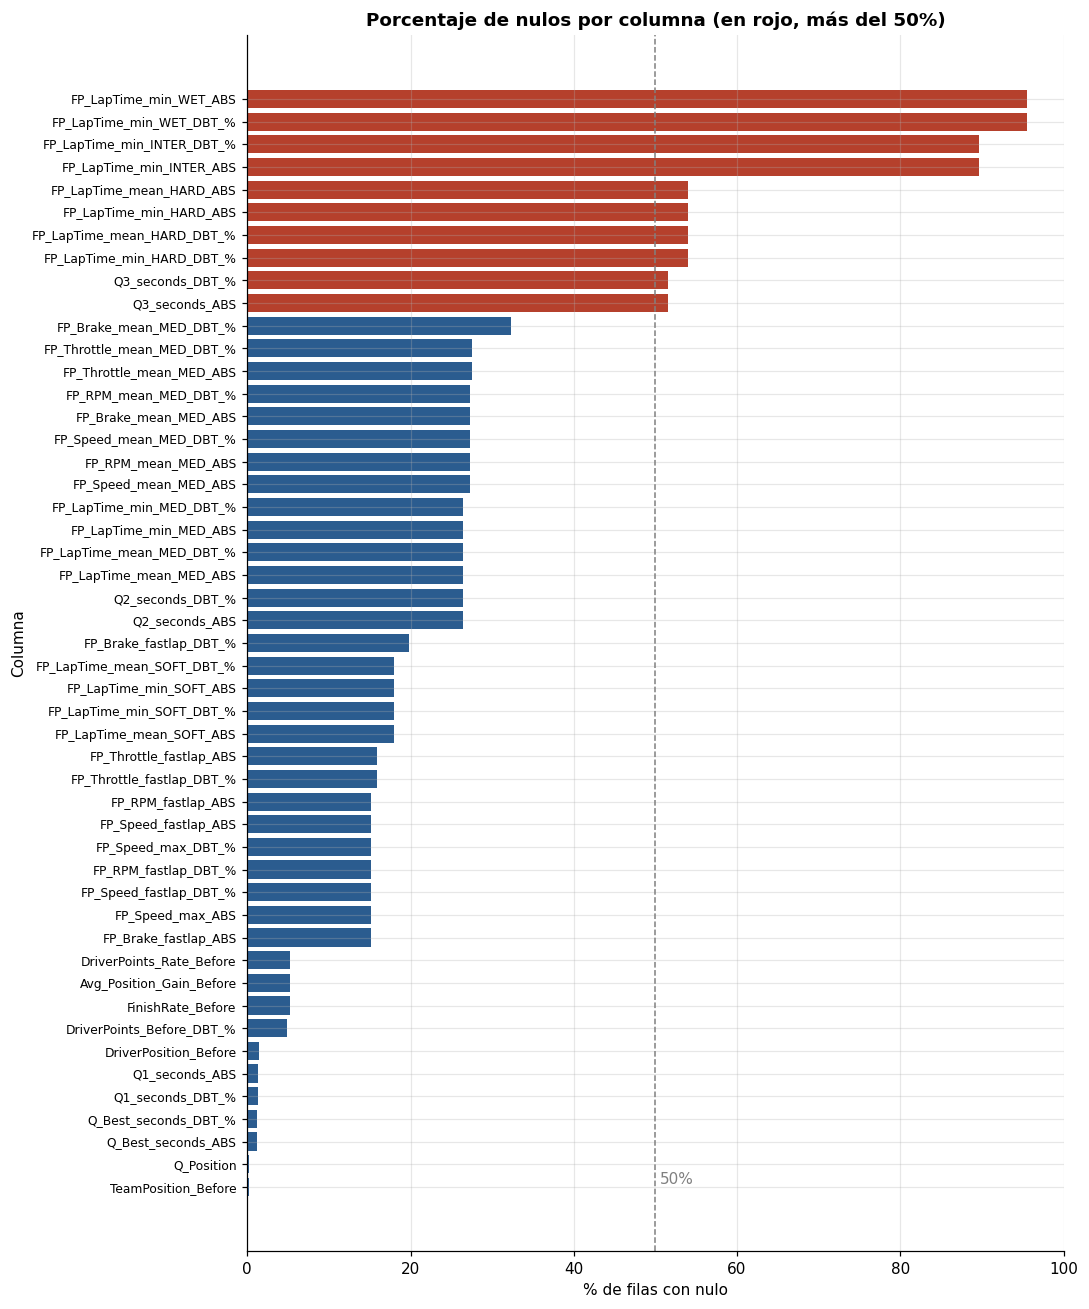

In [ ]:
nulos = df_raw.isna().sum()
tabla_nulos = (
    pd.DataFrame({"nulos": nulos, "porcentaje": nulos / len(df_raw) * 100})
    .query("nulos > 0")
    .sort_values("porcentaje", ascending=True)
)
resumen_nulos = pd.DataFrame({"Columnas": {
    "Con al menos un nulo": len(tabla_nulos),
    "Con más del 50% de nulos": int((tabla_nulos.porcentaje > 50).sum()),
    "Sin ningún nulo": df_raw.shape[1] - len(tabla_nulos),
}})
mostrar(resumen_nulos, "Resumen de nulos")

fig, ax = plt.subplots(figsize=(10, 12))
colores = ["#B5402C" if p > 50 else "#2B5C8F" for p in tabla_nulos.porcentaje]
ax.barh(tabla_nulos.index, tabla_nulos.porcentaje, color=colores)
ax.axvline(50, color="gray", linestyle="--", linewidth=1)
ax.text(50.5, 0, "50%", color="gray", va="bottom")
ax.tick_params(axis="y", labelsize=8)
ax.set_xlim(0, 100)
ax.set_xlabel("% de filas con nulo")
ax.set_ylabel("Columna")
ax.set_title("Porcentaje de nulos por columna (en rojo, más del 50%)")
plt.tight_layout()
plt.show()

**Lectura:** 49 de las 59 columnas tienen algún nulo y 10 pasan el 50%. Los peores
**no son errores: los genera el formato de la competencia**.

- `FP_LapTime_min_WET_*` (**95,5%**) e `INTER_*` (**89,6%**): casi nunca llueve.
- `FP_LapTime_min_HARD_*` (**54%**): no todos prueban el compuesto duro en prácticas.
- `Q3_seconds_*` (**51,5%**) y `Q2_seconds_*` (**26,4%**): a Q3 solo llegan los 10 mejores y
  a Q2, los 15 mejores. Los números lo confirman: con 20 autos, Q2 cubre 15 de 20 (75%) y Q3,
  10 de 20 (50%), muy cerca del **73,6%** y el **48,5%** que se observan.

El resto de los nulos de prácticas son vueltas que no quedaron registradas.

### Columnas constantes

Una columna que tiene siempre el mismo valor no sirve para distinguir filas.

In [ ]:
constantes = df_raw.columns[df_raw.nunique(dropna=False) == 1].tolist()
print(f"Columnas constantes: {len(constantes)}", "→ " + ", ".join(constantes) if constantes else "")

Columnas constantes: 0 


**Lectura:** no hay columnas constantes. Todas varían entre filas, así que por este chequeo no
se elimina ninguna.

### Duplicados: primero hay que elegir la clave

No existe "el" duplicado: primero hay que decidir qué define una fila única. Acá la clave
natural es **un piloto en un GP** (`DriverId`, `Year`, `RoundNumber`). También se prueban otras
claves para ver si algo más se rompe.

In [ ]:
verificaciones = {
    "Piloto único por GP": ["DriverId", "Year", "RoundNumber"],
    "Dorsal único por GP": ["DriverNumber", "Year", "RoundNumber"],
    "Posición final única por GP": ["Year", "RoundNumber", "RACE_Position"],
    "Grilla única por GP": ["Year", "RoundNumber", "Q_GridPosition"],
    "Clasificación única por GP": ["Year", "RoundNumber", "Q_Position"],
    "Piloto + escudería por GP": ["DriverId", "TeamId", "Year", "RoundNumber"],
}
dup = pd.Series({nombre: df_raw.duplicated(subset=c).sum() for nombre, c in verificaciones.items()})
dup["Filas idénticas en todas las columnas"] = df_raw.duplicated().sum()
mostrar(dup.to_frame("Filas repetidas"), "Filas repetidas según cada clave")

filas_dup = df_raw[df_raw.duplicated(subset=["DriverId", "Year", "RoundNumber"], keep=False)]
mostrar(
    filas_dup[["DriverId", "Year", "RoundNumber", "TeamId", "Q_Position", "Q_GridPosition", "RACE_Position"]]
    .sort_values(["Year", "RoundNumber", "DriverId"]),
    f"Las {len(filas_dup)} filas que comparten piloto y GP", decimales=0,
)

,Filas repetidas
Piloto único por GP,10
Dorsal único por GP,10
Posición final única por GP,10
Grilla única por GP,19
Clasificación única por GP,20
Piloto + escudería por GP,10
Filas idénticas en todas las columnas,0


,DriverId,Year,RoundNumber,TeamId,Q_Position,Q_GridPosition,RACE_Position
70,albon,2023,11,williams,16,16,11
71,albon,2023,11,williams,16,16,11
1428,kevin_magnussen,2023,11,haas,19,19,17
1429,kevin_magnussen,2023,11,haas,19,19,17
1746,leclerc,2023,11,ferrari,6,6,7
1747,leclerc,2023,11,ferrari,6,6,7
2165,norris,2023,11,mclaren,3,3,2
2166,norris,2023,11,mclaren,3,3,2
3216,sargeant,2023,11,williams,20,20,18
3217,sargeant,2023,11,williams,20,20,18


**Lectura:** no hay dos filas idénticas en todo, pero la clave piloto-GP encuentra **10 filas
repetidas**: **5 pilotos en 2023-Ronda 11** y **5 en 2025-Ronda 16**. Cada par tiene el mismo
equipo, la misma clasificación, la misma grilla y el mismo resultado: es **la misma fila
cargada dos veces**, no un piloto que cambió de equipo. Hay que sacarlas antes de modelar. Por
qué se duplicaron justo esas dos fechas queda para revisar en el pipeline.

### El caso de la grilla: ceros que no son una posición

La clave de grilla marca **más** repetidos que la de piloto (19 contra 10). No es otro grupo de
filas duplicadas: en algunas carreras varios pilotos tienen grilla **0**. Antes de hablar de
"ceros raros", hay que contarlos.

In [ ]:
ceros_grilla = df_raw[df_raw["Q_GridPosition"] == 0]
tabla_ceros_grilla = pd.DataFrame({"Valor": {
    "Filas con Q_GridPosition = 0": len(ceros_grilla),
    "% del dataset": f"{len(ceros_grilla) / len(df_raw) * 100:.1f}%".replace(".", ","),
    "De esas, con Q_Position cargada": int(ceros_grilla["Q_Position"].notna().sum()),
    "De esas, con Q_Position vacía": int(ceros_grilla["Q_Position"].isna().sum()),
}})
mostrar(tabla_ceros_grilla, "Filas con grilla 0")
mostrar(ceros_grilla[["DriverId", "Year", "RoundNumber", "Q_Position", "Q_GridPosition", "RACE_Position"]].head(10),
        "Ejemplos: primeras 10 filas con grilla 0", decimales=0)

,Valor
Filas con Q_GridPosition = 0,45
% del dataset,"1,2%"
"De esas, con Q_Position cargada",44
"De esas, con Q_Position vacía",1


,DriverId,Year,RoundNumber,Q_Position,Q_GridPosition,RACE_Position
3,albon,2019,3,—,0,10
16,albon,2019,16,19,0,5
512,bottas,2022,11,12,0,11
592,brendon_hartley,2018,10,20,0,20
707,gasly,2019,4,20,0,17
755,gasly,2021,14,6,0,19
776,gasly,2022,13,19,0,12
777,gasly,2022,14,12,0,9
917,giovinazzi,2021,11,14,0,13
972,grosjean,2020,2,20,0,13


**Lectura:** son **45 filas** (1,2%). En F1 el 0 no es una posición: son pilotos que largaron
desde boxes o que no tuvieron lugar asignado en la grilla. Por eso 44 de las 45 sí tienen
posición de clasificación. En la limpieza se pasan a nulo.

### La variable objetivo: `RACE_Position`

Antes de buscar relaciones hay que ver cómo se reparte lo que se quiere predecir. Si una
posición concentrara la mayoría de las filas o hubiera valores raros, cambiaría todo lo demás.

,count,mean,std,min,25%,50%,75%,max,nulos,% en posiciones 1–20
RACE_Position,"3754,00","10,57","5,82","1,00","6,00","11,00","16,00","22,00",0,"99,31"


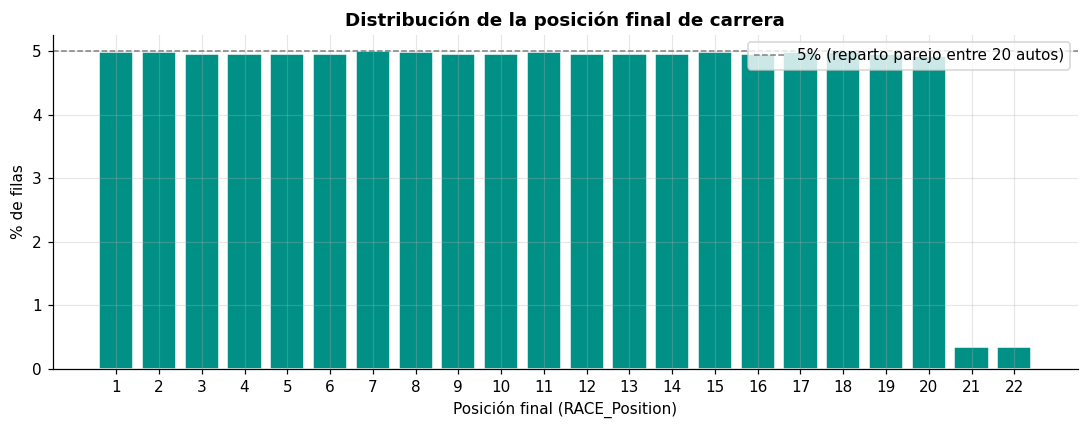

In [ ]:
resumen_obj = df_raw[target].describe().to_frame("RACE_Position").T
resumen_obj["nulos"] = df_raw[target].isna().sum()
resumen_obj["% en posiciones 1–20"] = df_raw[target].le(20).mean() * 100
mostrar(resumen_obj, "Resumen de RACE_Position")

pct_pos = df_raw[target].value_counts(normalize=True).sort_index() * 100
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(pct_pos.index, pct_pos.values, color="#009086", edgecolor="white")
ax.axhline(5, color="gray", linestyle="--", linewidth=1, label="5% (reparto parejo entre 20 autos)")
ax.set_xticks(range(1, 23))
ax.set_xlabel("Posición final (RACE_Position)")
ax.set_ylabel("% de filas")
ax.set_title("Distribución de la posición final de carrera")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

**Lectura:** el objetivo **no tiene nulos**, va de 1 a 22, con media 10,57 y mediana 11. Las
posiciones 1 a 20 tienen casi la misma cantidad de filas (**cerca del 5% cada una**) y solo el
**0,7%** cae en 21 o 22 (temporadas con más de 20 autos).

### ¿Qué significa cada columna?

Cada fila es un piloto en un GP. Las columnas de rendimiento se nombran
`{Categoría}_{métrica}_{ABS|DBT_%}`:

- `_ABS` = valor absoluto de la métrica.
- `_DBT_%` = distancia porcentual al **mejor de esa carrera**:
  `(valor − mejor de la carrera) / mejor de la carrera × 100`. `0%` es el mejor de la carrera.

#### Identificación

| Columna | Qué mide |
|---|---|
| `DriverId` | Identificador del piloto |
| `DriverNumber` | Número de dorsal del piloto |
| `TeamId` | Identificador de la escudería |
| `Year` | Temporada (2018–2026) |
| `RoundNumber` | Número de fecha del GP en el calendario |

#### Clasificación (qualy)

| Columna | Qué mide |
|---|---|
| `Q_Position` | Posición final de la clasificación |
| `Q_GridPosition` | Posición de largada (con las penalizaciones aplicadas) |
| `Q1_seconds_ABS` / `Q1_seconds_DBT_%` | Mejor tiempo de Q1: en segundos / distancia % al mejor |
| `Q2_seconds_ABS` / `Q2_seconds_DBT_%` | Mejor tiempo de Q2 |
| `Q3_seconds_ABS` / `Q3_seconds_DBT_%` | Mejor tiempo de Q3 |
| `Q_Best_seconds_ABS` / `Q_Best_seconds_DBT_%` | Mejor tiempo entre Q1, Q2 y Q3 |

#### Campeonato antes de la fecha

| Columna | Qué mide |
|---|---|
| `DriverPosition_Before` | Posición del piloto en el campeonato antes de este GP |
| `DriverPoints_Before` | Puntos acumulados del piloto antes de este GP |
| `DriverPoints_Before_DBT_%` | Distancia % de los puntos del piloto a los del líder (0% = líder) |
| `TeamPosition_Before` | Posición de la escudería antes de este GP |
| `TeamPoints_Before` | Puntos acumulados de la escudería antes de este GP |
| `Races_Before` | Carreras que corrió el piloto en la temporada antes de esta |
| `FinishRate_Before` | Proporción de carreras terminadas antes de esta (0 a 1) |
| `DriverPoints_Rate_Before` | Puntos obtenidos sobre los posibles: `DriverPoints_Before / (Races_Before × 25)` |
| `Avg_Position_Gain_Before` | Promedio de posiciones ganadas o perdidas (`grilla − llegada`) en las carreras previas |

#### Carrera

| Columna | Qué mide |
|---|---|
| `RACE_Position` | **Variable objetivo**: posición final de carrera (1–22) |

#### Prácticas (FP1 + FP2 + FP3 unificadas)

| Columna | Qué mide |
|---|---|
| `FP_LapTime_min_{SOFT/MED/HARD/INTER/WET}_ABS` | Mejor vuelta del fin de semana con ese compuesto |
| `FP_LapTime_min_{compuesto}_DBT_%` | Distancia % de esa mejor vuelta a la mejor de la carrera |
| `FP_LapTime_mean_{SOFT/MED/HARD}_ABS` | Vuelta promedio con ese compuesto |
| `FP_LapTime_mean_{compuesto}_DBT_%` | Distancia % de la vuelta promedio a la mejor de la carrera |
| `FP_Throttle_fastlap_ABS/DBT_%` | Acelerador medio (%) en la vuelta más rápida |
| `FP_Speed_fastlap_ABS/DBT_%` | Velocidad media (km/h) en la vuelta más rápida |
| `FP_Speed_max_ABS/DBT_%` | Velocidad máxima (km/h) en la vuelta más rápida |
| `FP_RPM_fastlap_ABS/DBT_%` | RPM medio en la vuelta más rápida |
| `FP_Brake_fastlap_ABS/DBT_%` | Frenado medio (%) en la vuelta más rápida |
| `FP_{Throttle/Speed/RPM/Brake}_mean_MED_ABS/DBT_%` | Las mismas métricas, promediadas sobre las vueltas con compuesto medio |

> El detalle completo está en `include/output/columnas.md`.

### Limpieza mínima

Antes de seguir se aplican tres correcciones. Todas se justificaron arriba y se cuentan acá:

1. **Sacar duplicados** por `(DriverId, Year, RoundNumber)`: las 10 filas cargadas dos veces.
2. **Pasar a nulo los ceros que no son datos reales**:
   - `Q_GridPosition = 0`: largada desde boxes o sin lugar en la grilla.
   - `DriverPosition_Before = 0` y `TeamPosition_Before = 0`: primera fecha de cada temporada,
     cuando todavía no hay campeonato.
   - Telemetría en 0: vueltas sin registro (nadie da una vuelta a 0 km/h).

In [ ]:
df = df_raw.copy()
limpieza = {}

antes = len(df)
# 1. Identificar las rondas (Año y Número de Ronda) que contienen pilotos duplicados
claves_duplicadas = df[df.duplicated(subset=["DriverId", "Year", "RoundNumber"])][["Year", "RoundNumber"]].drop_duplicates()

# 2. Eliminar todas las filas correspondientes a esas rondas completas
rondas_a_borrar = list(claves_duplicadas.itertuples(index=False, name=None))
filas_a_mantener = ~df.set_index(["Year", "RoundNumber"]).index.isin(rondas_a_borrar)
df = df[filas_a_mantener].reset_index(drop=True)

limpieza["Filas eliminadas (rondas con duplicados completas)"] = antes - len(df)
limpieza["Rondas eliminadas por duplicados"] = len(rondas_a_borrar)

for c in ["Q_GridPosition", "DriverPosition_Before", "TeamPosition_Before"]:
    limpieza[f"{c}: ceros pasados a nulo"] = int((df[c] == 0).sum())
    df[c] = df[c].replace(0, np.nan)

tel_abs = [c for c in df.columns
           if c.endswith("_ABS") and any(k in c for k in ["Throttle", "Speed", "RPM", "Brake"])]
total_ceros_tel = 0
for c in tel_abs:
    n_ceros = int((df[c] == 0).sum())
    if n_ceros:
        df[c] = df[c].replace(0, np.nan)
        total_ceros_tel += n_ceros
limpieza[f"Telemetría ABS ({len(tel_abs)} columnas): ceros pasados a nulo"] = total_ceros_tel
limpieza["Filas del dataset limpio"] = df.shape[0]
limpieza["Columnas del dataset limpio"] = df.shape[1]

mostrar(pd.Series(limpieza).to_frame("Cantidad"), "Qué cambió con la limpieza (borrando rondas duplicadas completas)")

,Cantidad
Filas eliminadas (rondas con duplicados completas),50
Rondas eliminadas por duplicados,2
Q_GridPosition: ceros pasados a nulo,45
DriverPosition_Before: ceros pasados a nulo,182
TeamPosition_Before: ceros pasados a nulo,182
Telemetría ABS (9 columnas): ceros pasados a nulo,153
Filas del dataset limpio,3704
Columnas del dataset limpio,59


## Sección 2: Análisis univariado

Se describe cada variable por separado, **familia por familia**. Acá no se elige ninguna
candidata: entran todas las columnas de cada bloque. La reducción se decide en la Sección 3,
cuando se ve qué columnas repiten información.

In [ ]:
FAMILIAS = {
    "Clasificación": [
        "Q_Position", "Q_GridPosition",
        "Q1_seconds_ABS", "Q2_seconds_ABS", "Q3_seconds_ABS", "Q_Best_seconds_ABS",
        "Q1_seconds_DBT_%", "Q2_seconds_DBT_%", "Q3_seconds_DBT_%", "Q_Best_seconds_DBT_%",
    ],
    "Campeonato": [
        "DriverPosition_Before", "DriverPoints_Before", "DriverPoints_Before_DBT_%",
        "DriverPoints_Rate_Before", "TeamPosition_Before", "TeamPoints_Before",
        "Races_Before", "FinishRate_Before", "Avg_Position_Gain_Before",
    ],
    "FP tiempos": [
        "FP_LapTime_min_INTER_ABS", "FP_LapTime_min_INTER_DBT_%",
        "FP_LapTime_min_SOFT_ABS", "FP_LapTime_mean_SOFT_ABS",
        "FP_LapTime_min_SOFT_DBT_%", "FP_LapTime_mean_SOFT_DBT_%",
        "FP_LapTime_min_MED_ABS", "FP_LapTime_mean_MED_ABS",
        "FP_LapTime_min_MED_DBT_%", "FP_LapTime_mean_MED_DBT_%",
        "FP_LapTime_min_HARD_ABS", "FP_LapTime_mean_HARD_ABS",
        "FP_LapTime_min_HARD_DBT_%", "FP_LapTime_mean_HARD_DBT_%",
        "FP_LapTime_min_WET_ABS", "FP_LapTime_min_WET_DBT_%",
    ],
    "Telemetría": [
        "FP_Throttle_fastlap_ABS", "FP_Speed_fastlap_ABS", "FP_Speed_max_ABS",
        "FP_RPM_fastlap_ABS", "FP_Brake_fastlap_ABS",
        "FP_Throttle_fastlap_DBT_%", "FP_Speed_fastlap_DBT_%", "FP_Speed_max_DBT_%",
        "FP_RPM_fastlap_DBT_%", "FP_Brake_fastlap_DBT_%",
        "FP_Throttle_mean_MED_ABS", "FP_Speed_mean_MED_ABS", "FP_RPM_mean_MED_ABS",
        "FP_Brake_mean_MED_ABS", "FP_Throttle_mean_MED_DBT_%", "FP_Speed_mean_MED_DBT_%",
        "FP_RPM_mean_MED_DBT_%", "FP_Brake_mean_MED_DBT_%",
    ],
}
mostrar(pd.Series({k: len(v) for k, v in FAMILIAS.items()}).to_frame("Columnas"),
        "Familias que se analizan")

,Columnas
Clasificación,10
Campeonato,9
FP tiempos,16
Telemetría,18


### Posición, dispersión y nulos, familia por familia

Primero las medidas de posición (media, mediana) y de dispersión (desvío, mínimo, máximo), junto
con la **cobertura** de cada columna (% de filas con dato). La cobertura decide qué columnas ni
siquiera llegan a la etapa de redundancia.

In [ ]:
for nombre, cols_fam in FAMILIAS.items():
    resumen = df[cols_fam].describe().T
    resumen["cobertura_%"] = df[cols_fam].notna().mean() * 100
    resumen = resumen[["count", "cobertura_%", "mean", "std", "min", "50%", "max"]]
    resumen.columns = ["n", "cobertura %", "media", "desvío", "mín", "mediana", "máx"]
    resumen["n"] = resumen["n"].astype(int)
    mostrar(resumen.sort_values("cobertura %"), f"{nombre}: posición, dispersión y cobertura",
            gradiente=["cobertura %"])

,n,cobertura %,media,desvío,mín,mediana,máx
Q3_seconds_ABS,1795,"48,46","84,03","11,98","53,38","83,75","124,93"
Q3_seconds_DBT_%,1795,"48,46","1,00","1,29","0,00","0,81","27,62"
Q2_seconds_DBT_%,2726,"73,60","1,07","2,23","0,00","0,87","95,05"
Q2_seconds_ABS,2726,"73,60","84,35","11,87","53,65","83,74","126,69"
Q1_seconds_DBT_%,3653,"98,62","1,19","1,32","0,00","0,98","44,78"
Q1_seconds_ABS,3653,"98,62","85,16","12,33","53,90","84,11","141,61"
Q_Best_seconds_DBT_%,3658,"98,76","1,92","2,13","0,00","1,56","45,60"
Q_Best_seconds_ABS,3658,"98,76","84,49","12,00","53,38","83,51","141,61"
Q_GridPosition,3659,"98,79","10,48","5,78","1,00","10,00","22,00"
Q_Position,3697,"99,81","10,54","5,80","1,00","11,00","22,00"


,n,cobertura %,media,desvío,mín,mediana,máx
DriverPosition_Before,3470,"93,68","10,57","5,90","1,00","10,00","23,00"
DriverPoints_Rate_Before,3509,"94,74","0,21","0,25","0,00","0,09","1,05"
FinishRate_Before,3509,"94,74","0,86","0,16","0,00","0,90","1,00"
Avg_Position_Gain_Before,3509,"94,74","-0,21","2,46","-18,00","-0,17","14,00"
TeamPosition_Before,3516,"94,92","5,53","2,89","1,00","6,00","11,00"
DriverPoints_Before_DBT_%,3522,"95,09","74,61","29,73","0,00","88,97","100,00"
TeamPoints_Before,3704,"100,00","105,87","148,84","0,00","40,00","822,00"
DriverPoints_Before,3704,"100,00","52,74","77,83","0,00","18,00","549,00"
Races_Before,3704,"100,00","9,86","6,37","0,00","9,00","24,00"


,n,cobertura %,media,desvío,mín,mediana,máx
FP_LapTime_min_WET_DBT_%,168,"4,54","2,54","2,32","0,00","1,99","11,58"
FP_LapTime_min_WET_ABS,168,"4,54","104,02","13,48","81,26","100,49","143,21"
FP_LapTime_min_INTER_ABS,382,"10,31","99,18","11,89","76,14","97,75","129,37"
FP_LapTime_min_INTER_DBT_%,382,"10,31","2,88","2,80","0,00","2,23","20,66"
FP_LapTime_min_HARD_ABS,1703,"45,98","85,41","11,29","55,09","83,84","130,81"
FP_LapTime_mean_HARD_ABS,1703,"45,98","86,69","11,49","55,20","85,22","130,81"
FP_LapTime_min_HARD_DBT_%,1703,"45,98","1,93","1,90","0,00","1,58","30,63"
FP_LapTime_mean_HARD_DBT_%,1703,"45,98","2,39","2,05","0,00","2,13","31,60"
FP_LapTime_mean_MED_ABS,2718,"73,38","87,22","11,56","55,57","86,35","146,88"
FP_LapTime_min_MED_ABS,2718,"73,38","85,60","11,31","54,63","84,86","144,00"


,n,cobertura %,media,desvío,mín,mediana,máx
FP_Brake_mean_MED_DBT_%,2499,"67,47","27,50","68,99","0,00","16,45","800,00"
FP_Throttle_mean_MED_ABS,2662,"71,87","68,90","7,57","8,05","69,66","83,43"
FP_Speed_mean_MED_ABS,2663,"71,90","211,72","23,52","1,67","213,87","278,24"
FP_RPM_mean_MED_ABS,2673,"72,17","10244,53","719,02","441,33","10337,42","11764,00"
FP_Brake_mean_MED_ABS,2673,"72,17","18,43","8,03","7,08","17,45","100,00"
FP_Throttle_mean_MED_DBT_%,2676,"72,25","6,10","9,11","0,00","4,85","100,00"
FP_RPM_mean_MED_DBT_%,2684,"72,46","3,58","8,99","0,00","2,39","100,00"
FP_Speed_mean_MED_DBT_%,2684,"72,46","4,06","10,43","0,00","2,41","100,00"
FP_Brake_fastlap_DBT_%,2959,"79,89","25,12","33,21","0,00","19,74","578,05"
FP_Throttle_fastlap_ABS,3101,"83,72","71,68","6,52","8,05","72,28","84,05"


**Lectura:**

- **Clasificación:** la cobertura cae tanda a tanda porque no todos pasan de ronda: Q1 **98,6%**,
  Q2 **73,6%** y Q3 **48,5%**. En segundos (ABS) los tiempos van de 53 a 142 según el circuito.
  En distancia al mejor (DBT) la mediana está cerca del **1%**, pero hay máximos de hasta **95%**
  (vueltas con problemas).
- **Campeonato:** `DriverPoints_Before` va de 0 a **549** (media 52,90) y `TeamPoints_Before` de
  0 a **822** (media 106,19). `DriverPoints_Before_DBT_%` no tiene dato en el **4,9%** de las filas
  (la primera fecha de cada temporada).
- **FP tiempos:** la cobertura ordena el bloque: SOFT **82,0%**, MED **73,5%**, HARD **46,1%**,
  INTER **10,4%** y WET **4,5%**.
- **Telemetría:** cobertura entre **67,7%** y **84,4%**. `FP_Speed_fastlap_ABS` promedia
  **219 km/h** (máximo 263). Su versión DBT tiene mediana 2%, pero un máximo de **3.583%**: un
  valor imposible que se explica más abajo.

### Medidas de forma

La asimetría (*skew*) dice si la distribución tiene una cola larga hacia un lado. La curtosis
dice cuánto pesan los valores extremos. Para leerlas rápido se agrega una etiqueta con la forma:
**simétrica** (|skew| < 0,5), **algo asimétrica** (0,5 a 2) o **con cola larga** (más de 2).

In [ ]:
def etiqueta_forma(s):
    a = abs(s)
    return "simétrica" if a < 0.5 else "algo asimétrica" if a < 2 else "con cola larga"


for nombre, cols_fam in FAMILIAS.items():
    forma = df[cols_fam].agg(["skew", "kurt"]).T
    forma.columns = ["asimetría", "curtosis"]
    forma["forma"] = forma["asimetría"].map(etiqueta_forma)
    mostrar(forma, f"{nombre}: forma de la distribución")

,asimetría,curtosis,forma
Q_Position,"0,01","-1,19",simétrica
Q_GridPosition,"0,02","-1,19",simétrica
Q1_seconds_ABS,"0,58","0,55",algo asimétrica
Q2_seconds_ABS,"0,40","-0,07",simétrica
Q3_seconds_ABS,"0,45","0,16",simétrica
Q_Best_seconds_ABS,"0,47","0,24",simétrica
Q1_seconds_DBT_%,"12,61","346,71",con cola larga
Q2_seconds_DBT_%,"30,02","1190,42",con cola larga
Q3_seconds_DBT_%,"9,71","160,21",con cola larga
Q_Best_seconds_DBT_%,"6,21","76,87",con cola larga


,asimetría,curtosis,forma
DriverPosition_Before,"0,06","-1,16",simétrica
DriverPoints_Before,"2,15","4,94",con cola larga
DriverPoints_Before_DBT_%,"-1,20","0,30",algo asimétrica
DriverPoints_Rate_Before,"1,26","0,66",algo asimétrica
TeamPosition_Before,"0,01","-1,21",simétrica
TeamPoints_Before,"1,94","3,46",algo asimétrica
Races_Before,"0,19","-1,08",simétrica
FinishRate_Before,"-2,30","8,24",con cola larga
Avg_Position_Gain_Before,"-0,71","5,36",algo asimétrica


,asimetría,curtosis,forma
FP_LapTime_min_INTER_ABS,"0,40","-0,47",simétrica
FP_LapTime_min_INTER_DBT_%,"2,58","10,15",con cola larga
FP_LapTime_min_SOFT_ABS,"0,21","-0,05",simétrica
FP_LapTime_mean_SOFT_ABS,"0,20","-0,08",simétrica
FP_LapTime_min_SOFT_DBT_%,"18,05","372,86",con cola larga
FP_LapTime_mean_SOFT_DBT_%,"15,06","289,47",con cola larga
FP_LapTime_min_MED_ABS,"0,24","-0,07",simétrica
FP_LapTime_mean_MED_ABS,"0,23","-0,11",simétrica
FP_LapTime_min_MED_DBT_%,"18,62","470,13",con cola larga
FP_LapTime_mean_MED_DBT_%,"15,38","356,85",con cola larga


,asimetría,curtosis,forma
FP_Throttle_fastlap_ABS,"-1,10","3,44",algo asimétrica
FP_Speed_fastlap_ABS,"-1,96","11,82",algo asimétrica
FP_Speed_max_ABS,"-8,62","112,69",con cola larga
FP_RPM_fastlap_ABS,"-8,96","131,38",con cola larga
FP_Brake_fastlap_ABS,"7,74","74,96",con cola larga
FP_Throttle_fastlap_DBT_%,"11,00","147,04",con cola larga
FP_Speed_fastlap_DBT_%,"9,67","96,00",con cola larga
FP_Speed_max_DBT_%,"9,68","95,86",con cola larga
FP_RPM_fastlap_DBT_%,"10,09","106,70",con cola larga
FP_Brake_fastlap_DBT_%,"7,94","94,64",con cola larga


**Lectura:** los puntos acumulados tienen cola larga a la derecha (`DriverPoints_Before`
**2,15**, `TeamPoints_Before` **1,93**): muchos pilotos con pocos puntos y pocos con muchos.
`FinishRate_Before` está pegada a 1 (**−2,31**): casi todos terminan casi todas las carreras.

La diferencia más importante está en las prácticas: **las versiones ABS son simétricas y las
DBT tienen colas enormes** (`FP_LapTime_min_SOFT_DBT_%`: asimetría **18,13**; velocidad DBT:
**13,48**). Es la primera pista de que ABS y DBT no son intercambiables.

### La forma se ve en los histogramas

Seis distribuciones elegidas **para mostrar la forma**, no como selección: el objetivo, los
puntos, el ritmo de clasificación, el ritmo de prácticas y el par ABS/DBT de la velocidad. En
las columnas DBT el eje se corta en el percentil 99 para que la cola no aplaste el resto. El
título dice cuántas filas quedan afuera.

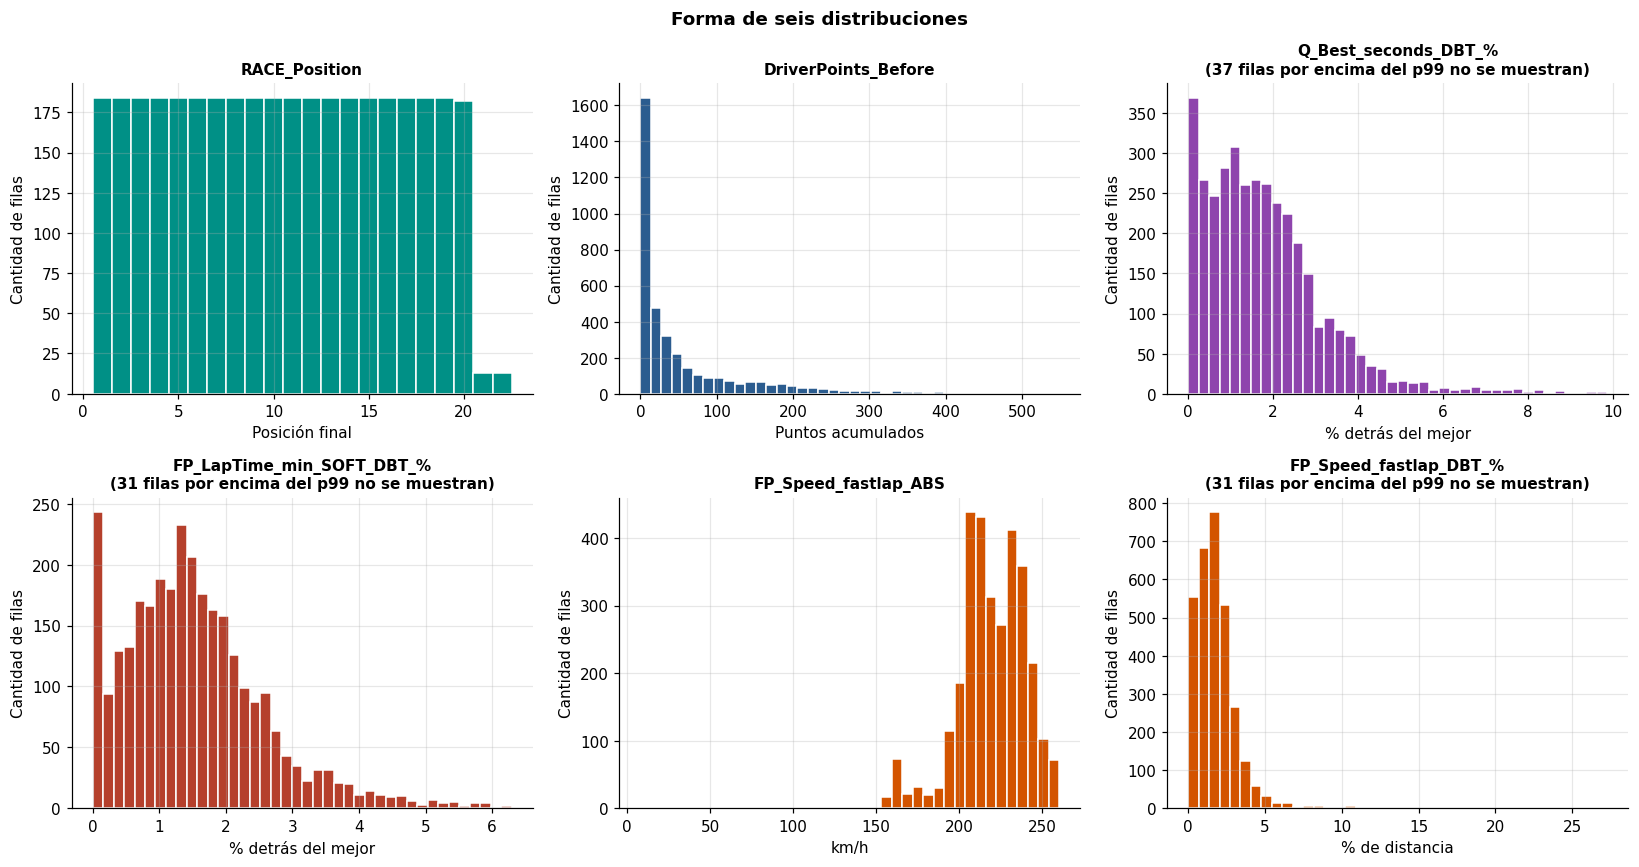

In [ ]:
def hist_recortado(ax, serie, titulo, xlabel, color, bins=40, recorte=None):
    s = serie.dropna()
    fuera = 0
    if recorte is not None:
        tope = np.percentile(s, recorte)
        fuera = int((s > tope).sum())
        s = s[s <= tope]
    ax.hist(s, bins=bins, color=color, edgecolor="white")
    ax.set_title(titulo + (f"\n({fuera} filas por encima del p{recorte} no se muestran)" if fuera else ""),
                 fontsize=10)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Cantidad de filas")


fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes[0, 0].hist(df[target], bins=np.arange(0.5, 23.5, 1), color="#009086", edgecolor="white")
axes[0, 0].set_title("RACE_Position", fontsize=10)
axes[0, 0].set_xlabel("Posición final")
axes[0, 0].set_ylabel("Cantidad de filas")
hist_recortado(axes[0, 1], df["DriverPoints_Before"], "DriverPoints_Before", "Puntos acumulados", "#2B5C8F")
hist_recortado(axes[0, 2], df["Q_Best_seconds_DBT_%"], "Q_Best_seconds_DBT_%",
               "% detrás del mejor", "#8E44AD", recorte=99)
hist_recortado(axes[1, 0], df["FP_LapTime_min_SOFT_DBT_%"], "FP_LapTime_min_SOFT_DBT_%",
               "% detrás del mejor", "#B5402C", recorte=99)
hist_recortado(axes[1, 1], df["FP_Speed_fastlap_ABS"], "FP_Speed_fastlap_ABS", "km/h", "#D35400")
hist_recortado(axes[1, 2], df["FP_Speed_fastlap_DBT_%"], "FP_Speed_fastlap_DBT_%",
               "% de distancia", "#D35400", recorte=99)
fig.suptitle("Forma de seis distribuciones", fontweight="bold")
plt.tight_layout()
plt.show()

**Lectura:** el objetivo es plano; los puntos muestran lo típico de la F1 (muchos con pocos
puntos, pocos con muchos); las DBT se amontonan cerca de 0 con una cola larga a la derecha. La
velocidad ABS tiene forma de campana. Los dos últimos paneles son **la misma métrica medida de
dos formas**, y la forma cambia por completo.

### Tiempos de vuelta por compuesto

Se comparan los cinco compuestos en sus dos versiones. En DBT se usa una escala que es lineal
cerca del 0 y logarítmica después (*symlog*). Así entran los ceros (el mejor de cada carrera) y
la cola larga en el mismo gráfico. En ABS alcanza con la escala lineal.

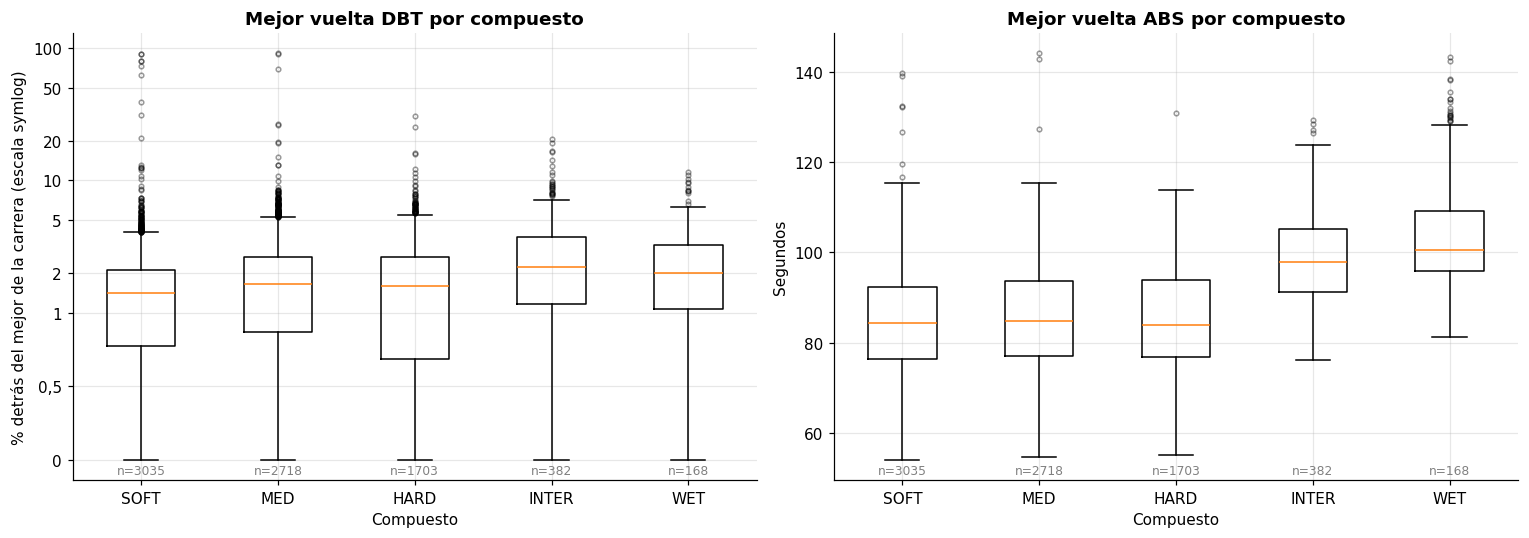

In [ ]:
compuestos = ["SOFT", "MED", "HARD", "INTER", "WET"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

datos_dbt = [df[f"FP_LapTime_min_{c}_DBT_%"].dropna() for c in compuestos]
axes[0].boxplot(datos_dbt, tick_labels=compuestos, flierprops={"markersize": 3, "alpha": 0.4})
axes[0].set_yscale("symlog", linthresh=1)
axes[0].set_yticks([0, 0.5, 1, 2, 5, 10, 20, 50, 100])
axes[0].set_yticklabels(["0", "0,5", "1", "2", "5", "10", "20", "50", "100"])
axes[0].set_title("Mejor vuelta DBT por compuesto")
axes[0].set_xlabel("Compuesto")
axes[0].set_ylabel("% detrás del mejor de la carrera (escala symlog)")

datos_abs = [df[f"FP_LapTime_min_{c}_ABS"].dropna() for c in compuestos]
axes[1].boxplot(datos_abs, tick_labels=compuestos, flierprops={"markersize": 3, "alpha": 0.4})
axes[1].set_title("Mejor vuelta ABS por compuesto")
axes[1].set_xlabel("Compuesto")
axes[1].set_ylabel("Segundos")

for ax, datos in zip(axes, [datos_dbt, datos_abs]):
    for i, d in enumerate(datos, start=1):
        ax.annotate(f"n={len(d)}", (i, 0), xycoords=("data", "axes fraction"),
                    xytext=(0, 4), textcoords="offset points", ha="center", fontsize=8, color="gray")
plt.tight_layout()
plt.show()

**Lectura:** en DBT, las cajas de SOFT, MED y HARD van de 0,7% a 2,6% del mejor, con la mediana
cerca del 1,5%, y la cola llega hasta 90%. En ABS las cajas de los tres compuestos secos casi se superponen: lo que más
cambia el tiempo en segundos es **el circuito**, no el compuesto. INTER y WET son más lentos
(pista mojada) y tienen muy pocos datos (**n = 390 y 168**), así que quedan marcados para el
descarte por falta de datos.

### Colas y valores extremos

Para cada columna de prácticas: la mediana (p50), el percentil 99 y el máximo. La última columna
dice **cuántas veces el máximo supera al p99**. Si es mucho mayor que 1, hay unos pocos valores
extremos muy alejados del resto.

In [ ]:
cols_cola = FAMILIAS["FP tiempos"] + FAMILIAS["Telemetría"]
filas = []
for c in cols_cola:
    d = df[c].dropna()
    p99 = np.percentile(d, 99)
    filas.append({
        "Variable": c,
        "n": len(d),
        "nulos %": df[c].isna().mean() * 100,
        "p50": np.percentile(d, 50),
        "p99": p99,
        "máx": d.max(),
        "máx ÷ p99": d.max() / p99 if p99 else np.nan,
    })
tabla_colas = pd.DataFrame(filas).set_index("Variable").sort_values("máx ÷ p99", ascending=False)
mostrar(tabla_colas, "Colas de las columnas de prácticas (ordenadas por máx ÷ p99)")

,n,nulos %,p50,p99,máx,máx ÷ p99
Variable,,,,,,
FP_LapTime_min_SOFT_DBT_%,3035,"18,06","1,40","6,30","90,28","14,33"
FP_LapTime_min_MED_DBT_%,2718,"26,62","1,66","7,48","90,85","12,15"
FP_LapTime_mean_MED_DBT_%,2718,"26,62","2,34","8,61","91,87","10,67"
FP_LapTime_mean_SOFT_DBT_%,3035,"18,06","1,82","10,92","92,60","8,48"
FP_Throttle_fastlap_DBT_%,3114,"15,93","4,28","16,63","100,00","6,01"
FP_RPM_fastlap_DBT_%,3137,"15,31","2,23","24,11","100,00","4,15"
FP_LapTime_min_HARD_DBT_%,1703,"54,02","1,58","7,48","30,63","4,09"
FP_LapTime_mean_HARD_DBT_%,1703,"54,02","2,13","8,07","31,60","3,92"
FP_Brake_fastlap_DBT_%,2959,"20,11","19,74","155,23","578,05","3,72"


La velocidad DBT tiene un máximo imposible. Para saber de dónde sale, se busca esa fila y se
recalcula el DBT a mano con las velocidades ABS de su carrera:

In [ ]:
vel = "FP_Speed_fastlap_ABS"
fila_max = df_raw.loc[df_raw["FP_Speed_fastlap_DBT_%"].idxmax()]
carrera = df_raw[(df_raw.Year == fila_max.Year) & (df_raw.RoundNumber == fila_max.RoundNumber)]
recalculado = (carrera[vel] - carrera[vel].min()) / carrera[vel].min() * 100
minimos = df_raw.groupby(["Year", "RoundNumber"])[vel].min()
mostrar(pd.DataFrame({"Valor": {
    "Carrera": f"{fila_max.Year} · ronda {fila_max.RoundNumber} · {fila_max.DriverId}",
    "Velocidad ABS del piloto (km/h)": fila_max[vel],
    "Velocidad ABS más baja de la carrera (km/h)": carrera[vel].min(),
    "Velocidad ABS mediana de la carrera (km/h)": carrera[vel].median(),
    "DBT del dataset (%)": fila_max["FP_Speed_fastlap_DBT_%"],
    "(v − mínimo) / mínimo × 100 (%)": recalculado[fila_max.name],
    "Carreras cuya velocidad mínima es menor a 100 km/h": int((minimos < 100).sum()),
}}), "De dónde sale el máximo de la velocidad DBT", decimales=2)

,Valor
Carrera,2026 · ronda 2 · albon
Velocidad ABS del piloto (km/h),"0,00"
Velocidad ABS más baja de la carrera (km/h),"0,00"
Velocidad ABS mediana de la carrera (km/h),"4,00"
DBT del dataset (%),"100,00"
(v − mínimo) / mínimo × 100 (%),—
Carreras cuya velocidad mínima es menor a 100 km/h,8


**Lectura:** la velocidad DBT tiene p99 **32,7** pero máximo **3.583**: el máximo es **más de
100 veces** el p99. La tabla de arriba muestra la causa. En telemetría, el DBT se calcula contra
la **lectura más baja de la carrera** (`(v − mínimo) / mínimo`, el recálculo da exactamente el
mismo número). En 2023-R11 esa lectura es de **6 km/h**, un dato roto, y dividir por 6 dispara
el porcentaje. En **8 carreras** la velocidad mínima está por debajo de 100 km/h. Las ABS, en
cambio, tienen máximos creíbles (velocidad **263 km/h**) y su cociente máx ÷ p99 está entre 1,0 y
1,3; solo el frenado llega a 2–3. En los tiempos de vuelta DBT el problema es menor: alguna vuelta
con problemas llega al 90%, pero el p99 está entre 6% y 11%.

### Categóricas: escuderías y pilotos

Las dos categóricas del dataset. Además de las frecuencias se calcula **η² (eta cuadrado)**:
qué parte de la variación de la posición final se explica solo sabiendo el equipo (o el
piloto). Va de 0 (nada) a 1 (todo).

In [ ]:
def eta2(numerica, categoria):
    d = pd.DataFrame({"x": numerica, "g": categoria}).dropna()
    media = d.x.mean()
    agg = d.groupby("g").x.agg(["size", "mean"])
    return (agg["size"] * (agg["mean"] - media) ** 2).sum() / ((d.x - media) ** 2).sum()


freq_team = pd.DataFrame({
    "Filas": df.TeamId.value_counts(),
    "% del dataset": df.TeamId.value_counts(normalize=True) * 100,
})
mostrar(freq_team, "Filas por escudería", decimales=1)

filas_piloto = df.DriverId.value_counts()
resumen_cat = pd.DataFrame({"Valor": {
    "Escuderías distintas": df.TeamId.nunique(),
    "Pilotos distintos": df.DriverId.nunique(),
    "Filas por piloto (mín / mediana / máx)":
        f"{filas_piloto.min()} / {filas_piloto.median():.0f} / {filas_piloto.max()}",
    "η² de RACE_Position según TeamId": round(eta2(df[target], df.TeamId), 3),
    "η² de RACE_Position según DriverId": round(eta2(df[target], df.DriverId), 3),
    "Spearman de DriverNumber con RACE_Position":
        round(pd.to_numeric(df.DriverNumber, errors="coerce").corr(df[target], method="spearman"), 3),
}})
mostrar(resumen_cat, "Resumen de las categóricas", decimales=3)

,Filas,% del dataset
TeamId,,
mclaren,368,"9,9"
red_bull,368,"9,9"
haas,368,"9,9"
mercedes,368,"9,9"
ferrari,368,"9,9"
williams,367,"9,9"
alpine,250,"6,7"
aston_martin,249,"6,7"
alfa,206,"5,6"


,Valor
Escuderías distintas,18
Pilotos distintos,44
Filas por piloto (mín / mediana / máx),1 / 60 / 184
η² de RACE_Position según TeamId,"0,323"
η² de RACE_Position según DriverId,"0,276"
Spearman de DriverNumber con RACE_Position,"0,004"


**Lectura:** los equipos que estuvieron todas las temporadas tienen **372 filas** cada uno; los
que cambiaron de nombre (Toro Rosso → AlphaTauri → RB, Force India → Racing Point → Aston
Martin) aparecen repartidos. Solo con saber el equipo se explica el **32,4%** de la variación del
resultado (η² = **0,324**); con el piloto, el **27,9%**. A primera vista son las variables más
fuertes del dataset. El problema es que esa fuerza **no se mantiene en el tiempo**, y eso se
analiza en la Sección 4. El dorsal no dice nada del resultado (ρ = **0,005**).

## Sección 3: Análisis bivariado

El bivariado es **selectivo**, como se acordó: no se cruza todo contra el objetivo. Hace tres
cosas:

1. Mide la relación más obvia: grilla contra resultado.
2. Decide entre la versión ABS y la DBT de cada métrica.
3. Muestra qué columnas repiten información dentro de cada bloque y arma una lista corta.

Las relaciones que importan para el modelo se prueban formalmente en las hipótesis (Sección 5).

### La grilla de salida contra el resultado

La posición de largada es la candidata más obvia. Las dos variables son posiciones de 1 a 22,
así que un diagrama de puntos común se vería como una cuadrícula. En su lugar se usan dos
paneles: un mapa de calor con cada combinación grilla-resultado y una tabla de conteos por
franjas.

,Valor
n,"3659,000"
Pearson,"0,623"
Spearman,"0,625"


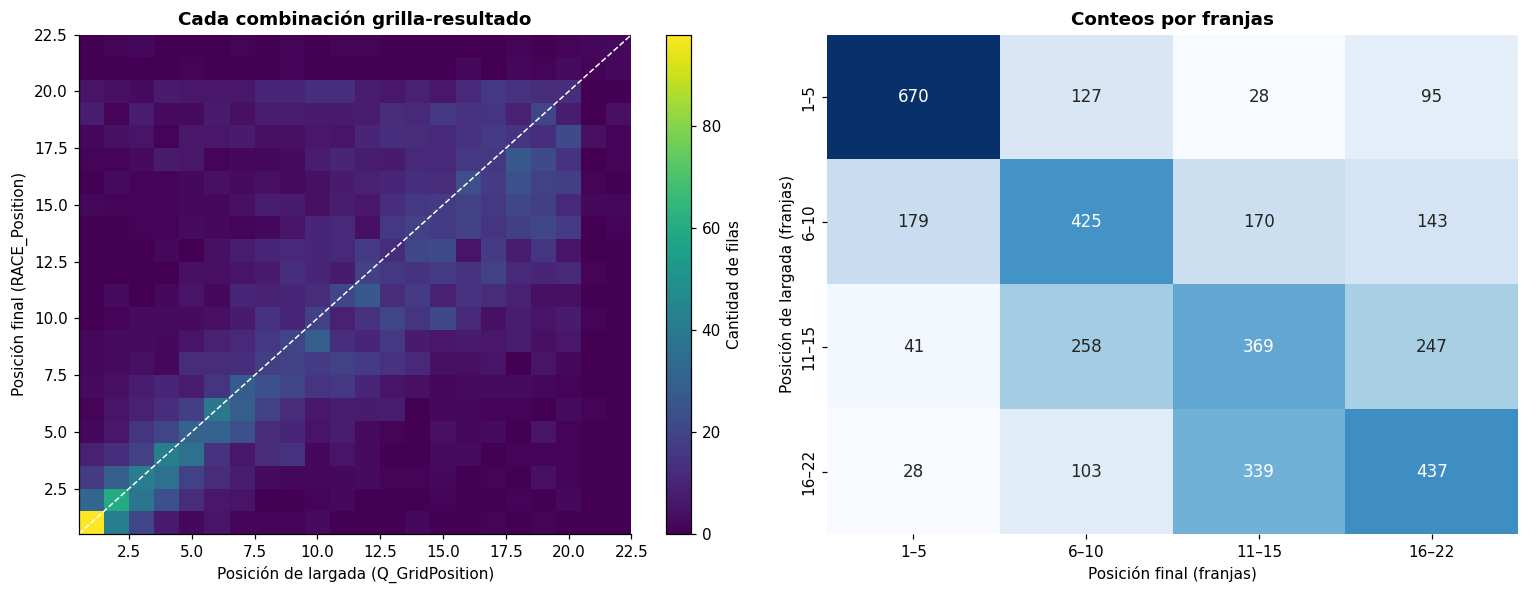

,Valor
Spearman² (parte del orden explicada) %,"39,0"
Largaron 1–5 y terminaron 1–5,670 de 920
Largaron 16–22 y terminaron 16–22,437 de 907


In [ ]:
FRANJAS = [0, 5, 10, 15, 22]
NOMBRES_FRANJAS = ["1–5", "6–10", "11–15", "16–22"]


def grafico_grilla_resultado(d):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

    h = axes[0].hist2d(d.Q_GridPosition, d[target],
                       bins=[np.arange(0.5, 23.5, 1), np.arange(0.5, 23.5, 1)],
                       cmap="viridis")
    axes[0].plot([0.5, 22.5], [0.5, 22.5], "--", color="white", linewidth=1)
    axes[0].set_xlabel("Posición de largada (Q_GridPosition)")
    axes[0].set_ylabel("Posición final (RACE_Position)")
    axes[0].set_title("Cada combinación grilla-resultado")
    axes[0].grid(False)
    fig.colorbar(h[3], ax=axes[0], label="Cantidad de filas")

    fb = pd.crosstab(pd.cut(d.Q_GridPosition, FRANJAS, labels=NOMBRES_FRANJAS),
                     pd.cut(d[target], FRANJAS, labels=NOMBRES_FRANJAS))
    sns.heatmap(fb, annot=True, fmt="d", cmap="Blues", ax=axes[1], cbar=False,
                annot_kws={"fontsize": 11})
    axes[1].set_xlabel("Posición final (franjas)")
    axes[1].set_ylabel("Posición de largada (franjas)")
    axes[1].set_title("Conteos por franjas")
    axes[1].grid(False)

    plt.tight_layout()
    plt.show()

    tabla = pd.DataFrame({"Valor": {
        "Spearman² (parte del orden explicada) %": d.Q_GridPosition.corr(d[target], method="spearman") ** 2 * 100,
        "Largaron 1–5 y terminaron 1–5": f"{fb.iloc[0, 0]} de {fb.iloc[0].sum()}",
        "Largaron 16–22 y terminaron 16–22": f"{fb.iloc[-1, -1]} de {fb.iloc[-1].sum()}",
    }})
    mostrar(tabla, "Qué tanto se conserva el orden", decimales=1)


d = df[["Q_GridPosition", target]].dropna()
mostrar(pd.DataFrame({"Valor": {"n": len(d),
                                "Pearson": d.Q_GridPosition.corr(d[target]),
                                "Spearman": d.Q_GridPosition.corr(d[target], method="spearman")}}),
        "Grilla contra resultado", decimales=3)
grafico_grilla_resultado(d)

**Lectura:** Pearson **0,623** y Spearman **0,625** (n = **3.699**). En el mapa, lo más claro
está sobre la diagonal: la mayoría termina cerca de donde largó. En la tabla: de los que largaron
entre los 5 primeros, **679 de 930** terminaron entre los 5 primeros; de los que largaron del 16
para atrás, **442 de 917** terminaron también ahí. La grilla explica cerca del **39%** del orden
de llegada: es el punto de partida del modelo, pero deja bastante sin explicar.

### ABS vs DBT: cuál de las dos versiones usar

Cada métrica de tiempos y telemetría viene en dos versiones, y hay que elegir una. El gráfico
muestra el problema de la ABS: su valor depende del circuito. La tabla de abajo muestra el
número que decide: cuánto se relaciona cada versión con el resultado.

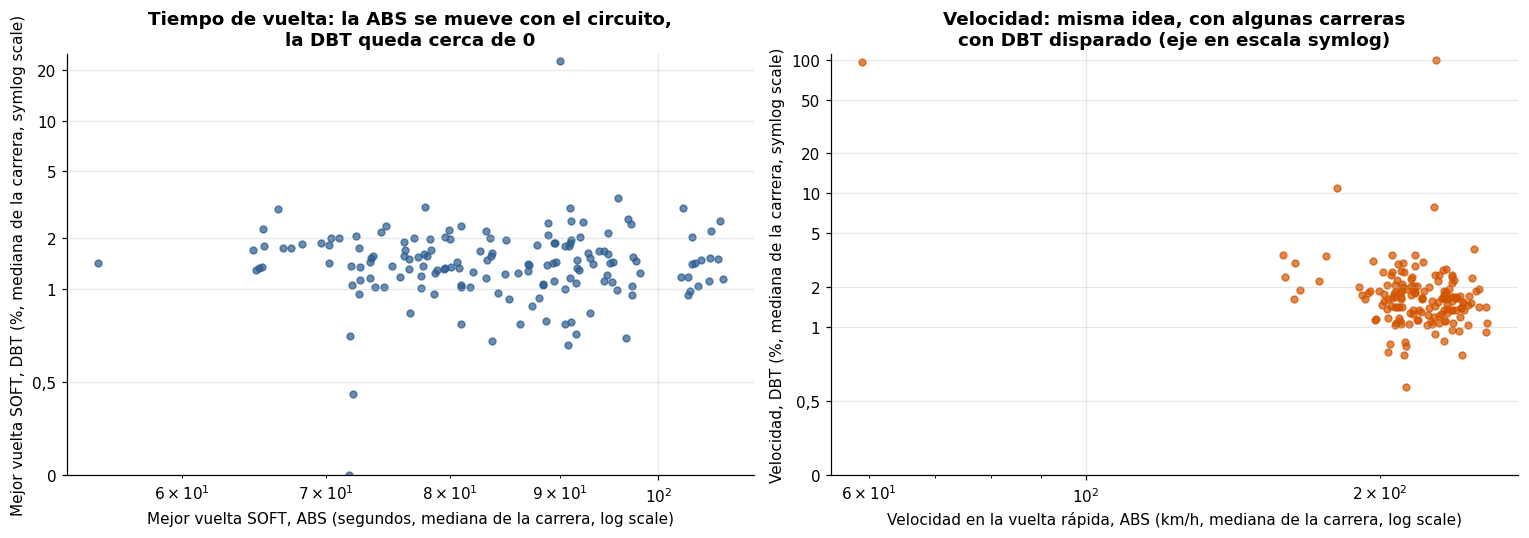

,mín entre carreras,máx entre carreras,std entre carreras
Mejor vuelta SOFT ABS (s),"54,8","107,2","11,1"
Mejor vuelta SOFT DBT (%),"0,0","22,6","1,8"
Velocidad ABS (km/h),"59,0","257,5","23,5"
Velocidad DBT (%),"0,6","100,0","10,9"


,n ABS,ρ ABS,n DBT,ρ DBT,Gana
Métrica,,,,,
FP_LapTime_min_SOFT,3035,"0,036",3035,"0,490",DBT
FP_LapTime_min_MED,2718,"0,040",2718,"0,416",DBT
FP_LapTime_min_HARD,1703,"0,066",1703,"0,339",DBT
FP_Speed_fastlap,3113,"-0,064",3137,"0,399",DBT
FP_Brake_fastlap,3120,"0,087",2959,"0,159",DBT
Q1_seconds,3653,"0,028",3653,"0,483",DBT
Q2_seconds,2726,"0,019",2726,"0,501",DBT
Q3_seconds,1795,"0,030",1795,"0,532",DBT
Q_Best_seconds,3658,"0,055",3658,"0,585",DBT


In [ ]:
por_carrera = df.groupby(["Year", "RoundNumber"]).agg(
    soft_abs=('FP_LapTime_min_SOFT_ABS', 'median'),
    soft_dbt=('FP_LapTime_min_SOFT_DBT_%', 'median'),
    speed_abs=('FP_Speed_fastlap_ABS', 'median'),
    speed_dbt=('FP_Speed_fastlap_DBT_%', 'median'),
).dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Soft lap times
axes[0].scatter(por_carrera.soft_abs, por_carrera.soft_dbt, s=20, color="#2B5C8F", alpha=0.7)
axes[0].set_xscale("log")
axes[0].set_yscale("symlog", linthresh=1)
axes[0].set_yticks([0, 0.5, 1, 2, 5, 10, 20, 50, 100])
axes[0].set_yticklabels(["0", "0,5", "1", "2", "5", "10", "20", "50", "100"])
axes[0].set_xlabel("Mejor vuelta SOFT, ABS (segundos, mediana de la carrera, log scale)")
axes[0].set_ylabel("Mejor vuelta SOFT, DBT (%, mediana de la carrera, symlog scale)")
axes[0].set_title("Tiempo de vuelta: la ABS se mueve con el circuito,\nla DBT queda cerca de 0")
axes[0].set_ylim(0, por_carrera.soft_dbt.max() * 1.1)

# Plot 2: Speed
axes[1].scatter(por_carrera.speed_abs, por_carrera.speed_dbt, s=20, color="#D35400", alpha=0.7)
axes[1].set_xscale("log")
axes[1].set_yscale("symlog", linthresh=1)
axes[1].set_yticks([0, 0.5, 1, 2, 5, 10, 20, 50, 100])
axes[1].set_yticklabels(["0", "0,5", "1", "2", "5", "10", "20", "50", "100"])
axes[1].set_xlabel("Velocidad en la vuelta rápida, ABS (km/h, mediana de la carrera, log scale)")
axes[1].set_ylabel("Velocidad, DBT (%, mediana de la carrera, symlog scale)")
axes[1].set_title("Velocidad: misma idea, con algunas carreras\ncon DBT disparado (eje en escala symlog)")
axes[1].set_ylim(0, por_carrera.speed_dbt.max() * 1.1)
plt.tight_layout()
plt.show()

rangos = pd.DataFrame({
    "mín entre carreras": [por_carrera.soft_abs.min(), por_carrera.soft_dbt.min(),
                           por_carrera.speed_abs.min(), por_carrera.speed_dbt.min()],
    "máx entre carreras": [por_carrera.soft_abs.max(), por_carrera.soft_dbt.max(),
                           por_carrera.speed_abs.max(), por_carrera.speed_dbt.max()],
    "std entre carreras": [por_carrera.soft_abs.std(), por_carrera.soft_dbt.std(),
                           por_carrera.speed_abs.std(), por_carrera.speed_dbt.std()],
}, index=["Mejor vuelta SOFT ABS (s)", "Mejor vuelta SOFT DBT (%)",
          "Velocidad ABS (km/h)", "Velocidad DBT (%)"])
mostrar(rangos, "Rango y desviación estándar de la mediana por carrera", decimales=1)

pares_abs_dbt = [
    ("FP_LapTime_min_SOFT_ABS", "FP_LapTime_min_SOFT_DBT_%"),
    ("FP_LapTime_min_MED_ABS", "FP_LapTime_min_MED_DBT_%"),
    ("FP_LapTime_min_HARD_ABS", "FP_LapTime_min_HARD_DBT_%"),
    ("FP_Speed_fastlap_ABS", "FP_Speed_fastlap_DBT_%"),
    ("FP_Brake_fastlap_ABS", "FP_Brake_fastlap_DBT_%"),
    ("Q1_seconds_ABS", "Q1_seconds_DBT_%"),
    ("Q2_seconds_ABS", "Q2_seconds_DBT_%"),
    ("Q3_seconds_ABS", "Q3_seconds_DBT_%"),
    ("Q_Best_seconds_ABS", "Q_Best_seconds_DBT_%"),
]
filas = []
for a, b in pares_abs_dbt:
    da = df[[a, target]].dropna()
    db = df[[b, target]].dropna()
    ra = da[a].corr(da[target], method="spearman")
    rb = db[b].corr(db[target], method="spearman")
    filas.append({
        "Métrica": a.replace("_ABS", ""),
        "n ABS": len(da), "ρ ABS": ra,
        "n DBT": len(db), "ρ DBT": rb,
        "Gana": "DBT" if abs(rb) > abs(ra) else "ABS",
    })
tabla_abs_dbt = pd.DataFrame(filas).set_index("Métrica")
mostrar(tabla_abs_dbt, "Spearman de cada versión con RACE_Position", decimales=3)

**Lectura:** en segundos, la mejor vuelta con blandos va de **54,8 a 107,2 s** según la carrera:
eso es el largo del circuito, no el piloto. En DBT, la misma métrica queda entre **0 y 22,6%**,
comparable entre circuitos. La velocidad DBT tiene algunas carreras con medianas absurdas (hasta
**3.224%**), por el problema de la lectura mínima que se vio antes.

En la tabla gana la DBT en **las nueve métricas**, y por mucho. Por ejemplo, SOFT **0,488 contra
0,036** y Q_Best **0,585 contra 0,055**. Con la ABS casi no hay relación con el resultado, porque
lo que mide es el circuito.

**Decisión:** para tiempos de vuelta y telemetría se usa la versión **DBT**. Las ABS salen del
dataset. La única excepción es el cálculo del desgaste (H6 y H7), que necesita la vuelta
promedio y la mejor en segundos. Ese cálculo lo va a hacer el pipeline (Sección 8), así que las
ABS no hace falta conservarlas como columnas.

### Telemetría: ¿cuántas columnas hacen falta?

La telemetría tiene 18 columnas: cuatro canales (acelerador, velocidad, RPM y freno), medidos de
dos formas (vuelta rápida y promedio con medios) y en dos versiones (ABS y DBT). La matriz de
correlaciones muestra si cada columna aporta algo distinto o si varias dicen lo mismo. Se muestra
solo la mitad de abajo, porque la de arriba es igual.

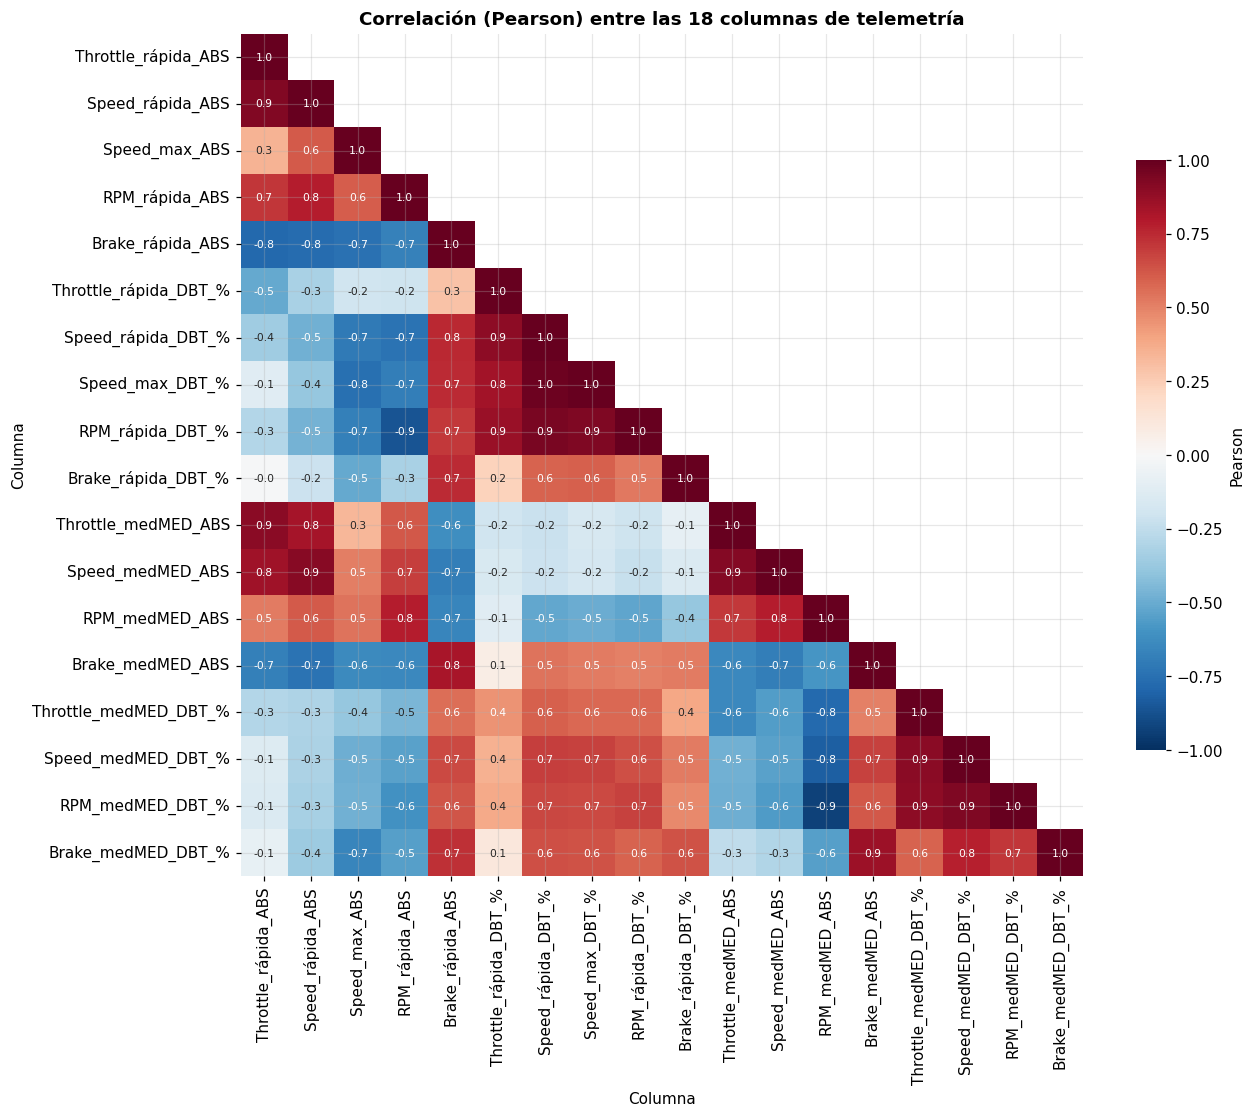

,|r| medio con el resto
FP_Speed_fastlap_DBT_%,"0,752"
FP_Speed_max_DBT_%,"0,738"
FP_RPM_fastlap_DBT_%,"0,720"
FP_Speed_mean_MED_DBT_%,"0,689"
FP_RPM_mean_MED_DBT_%,"0,677"
FP_Throttle_mean_MED_DBT_%,"0,620"
FP_Brake_mean_MED_DBT_%,"0,589"
FP_Throttle_fastlap_DBT_%,"0,517"
FP_Brake_fastlap_DBT_%,"0,497"


In [ ]:
bloque_tel = FAMILIAS["Telemetría"]
corr_tel = df[bloque_tel].corr()
etiquetas_cortas = [c.replace("FP_", "").replace("_fastlap", "_rápida").replace("_mean_MED", "_medMED")
                    for c in bloque_tel]
mascara = np.triu(np.ones_like(corr_tel, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr_tel, mask=mascara, annot=True, fmt=".1f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, annot_kws={"fontsize": 7}, xticklabels=etiquetas_cortas,
            yticklabels=etiquetas_cortas, cbar_kws={"label": "Pearson", "shrink": 0.7}, ax=ax)
ax.set_title("Correlación (Pearson) entre las 18 columnas de telemetría")
ax.set_xlabel("Columna")
ax.set_ylabel("Columna")
plt.tight_layout()
plt.show()

bloque_tel_dbt = [c for c in bloque_tel if c.endswith("_DBT_%")]
corr_abs = df[bloque_tel_dbt].corr().abs()
representatividad = ((corr_abs.sum() - 1) / (len(corr_abs) - 1)).sort_values(ascending=False)
mostrar(representatividad.to_frame("|r| medio con el resto"),
        "Cuánto se parece cada métrica DBT al resto del bloque", decimales=3)

pares = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool)).stack()
pares = pares[pares > 0.75].sort_values(ascending=False)
pares.index.names = ["Columna A", "Columna B"]
mostrar(pares.to_frame("|r|"), "Pares del bloque DBT que casi se copian (|r| > 0,75)", decimales=3)

**Lectura:** el bloque se repite mucho. `FP_Speed_fastlap_DBT_%` correlaciona **0,994** con la
velocidad máxima y **0,984** con las RPM de la misma vuelta: son prácticamente la misma columna.
Alcanza con **una sola columna de telemetría**, y la elegida es la **velocidad de la vuelta
rápida**: es de las que más se parecen al resto del bloque (**0,27**) y la que más se relaciona
con el resultado (**−0,303**). Que sea la mejor del bloque no quiere decir que sirva para el
modelo: eso se prueba en H3.

### Columnas que repiten información en los otros bloques

Fuera de la telemetría quedan cuatro decisiones: clasificación, campeonato, ritmo de prácticas
y las variables de fecha. Cada una se resuelve mirando el par de columnas que la define.

In [ ]:
pares_clave = [
    ("Q_Position", "Q_GridPosition"),
    ("DriverPoints_Before_DBT_%", "DriverPoints_Rate_Before"),
    ("DriverPoints_Before_DBT_%", "DriverPosition_Before"),
    ("DriverPosition_Before", "TeamPosition_Before"),
    ("DriverPoints_Before", "TeamPoints_Before"),
    ("DriverPoints_Before", "DriverPoints_Before_DBT_%"),
    ("FP_LapTime_min_SOFT_DBT_%", "FP_LapTime_mean_SOFT_DBT_%"),
    ("FP_LapTime_min_MED_DBT_%", "FP_LapTime_mean_MED_DBT_%"),
    ("FP_LapTime_min_HARD_DBT_%", "FP_LapTime_mean_HARD_DBT_%"),
    ("FP_LapTime_min_SOFT_DBT_%", "FP_LapTime_min_MED_DBT_%"),
    ("FP_LapTime_min_MED_DBT_%", "FP_LapTime_min_HARD_DBT_%"),
    ("Q_Best_seconds_DBT_%", "FP_LapTime_min_SOFT_DBT_%"),
    ("RoundNumber", "Races_Before"),
]
filas = []
for a, b in pares_clave:
    d = df[[a, b]].dropna()
    filas.append({"Columna A": a, "Columna B": b,
                  "Spearman": d[a].corr(d[b], method="spearman"),
                  "Pearson": d[a].corr(d[b]), "n": len(d)})
tabla_redundancia = pd.DataFrame(filas).set_index(["Columna A", "Columna B"])
mostrar(tabla_redundancia, "Pares que definen cada decisión de redundancia", decimales=3)

**Lectura y decisión por bloque:**

- **Clasificación:** `Q_Position` sale porque es casi igual a la grilla (**0,961**). Además, la
  grilla ya tiene aplicadas las penalizaciones.
- **Campeonato:** se queda `DriverPoints_Before_DBT_%` (distancia en puntos al líder). Las demás
  dicen lo mismo con otra escala: `DriverPoints_Rate_Before` (**−0,995**),
  `DriverPosition_Before` (**0,966**), `TeamPosition_Before` (**0,906**), `TeamPoints_Before`
  (**0,954**) y `DriverPoints_Before` (**−0,926**). Salen todas.
- **FP, mejor vuelta vs. vuelta promedio:** con el mismo compuesto, la vuelta promedio sigue de
  cerca a la mejor (Pearson **0,87 a 0,93**). Se queda la mejor vuelta. En la Sección 6 se
  comprueba que la promedio no agrega nada.
- **FP, entre compuestos:** SOFT, MED y HARD se parecen solo a medias (**0,54** y **0,37**). No
  son copias, así que se quedan los tres (H5 lo mira en detalle).
- **Clasificación vs. prácticas:** `Q_Best_seconds_DBT_%` y la mejor vuelta SOFT ordenan a los
  pilotos de forma parecida (Spearman **0,71**), pero mucho menos que los pares que se
  descartaron (0,90 o más). Se quedan las dos.
- **Fecha:** `RoundNumber` y `Races_Before` son casi la misma columna (**0,969**). Si sirven o
  no se prueba en H4.

### La lista corta del bivariado

Con la cobertura (Sección 2), la decisión ABS vs DBT y la redundancia resuelta, quedan **7
columnas candidatas**.

In [ ]:
SHORTLIST = {
    "Q_GridPosition": ("Clasificación", "Se queda en lugar de Q_Position (0,961 entre ellas)."),
    "Q_Best_seconds_DBT_%": ("Clasificación", "La de mayor relación con el resultado de la familia (0,585). Q1/Q2/Q3 se evalúan en H2."),
    "DriverPoints_Before_DBT_%": ("Campeonato", "Resume al resto del bloque (0,906 a 0,995 con las otras)."),
    "FP_LapTime_min_SOFT_DBT_%": ("FP tiempos", "La de mejor cobertura (82,0%). La vuelta promedio sigue a la mejor."),
    "FP_LapTime_min_MED_DBT_%": ("FP tiempos", "No es copia de SOFT (0,54) ni de HARD (0,37)."),
    "FP_LapTime_min_HARD_DBT_%": ("FP tiempos", "Única medida con compuesto duro. Cobertura 46,1%."),
    "FP_Speed_fastlap_DBT_%": ("Telemetría", "Representa al bloque (0,994 y 0,984 con velocidad máx. y RPM)."),
}
tabla_short = pd.DataFrame([
    {"Variable": c, "Familia": f, "Cobertura %": df[c].notna().mean() * 100, "Por qué pasa": m}
    for c, (f, m) in SHORTLIST.items()
]).set_index("Variable")
mostrar(tabla_short, f"Lista corta: {len(tabla_short)} columnas", decimales=1,
        texto_largo=True, gradiente=["Cobertura %"])

,Familia,Cobertura %,Por qué pasa
Variable,,,
Q_GridPosition,Clasificación,"98,8","Se queda en lugar de Q_Position (0,961 entre ellas)."
Q_Best_seconds_DBT_%,Clasificación,"98,8","La de mayor relación con el resultado de la familia (0,585). Q1/Q2/Q3 se evalúan en H2."
DriverPoints_Before_DBT_%,Campeonato,"95,1","Resume al resto del bloque (0,906 a 0,995 con las otras)."
FP_LapTime_min_SOFT_DBT_%,FP tiempos,"81,9","La de mejor cobertura (82,0%). La vuelta promedio sigue a la mejor."
FP_LapTime_min_MED_DBT_%,FP tiempos,"73,4","No es copia de SOFT (0,54) ni de HARD (0,37)."
FP_LapTime_min_HARD_DBT_%,FP tiempos,"46,0","Única medida con compuesto duro. Cobertura 46,1%."
FP_Speed_fastlap_DBT_%,Telemetría,"84,7","Representa al bloque (0,994 y 0,984 con velocidad máx. y RPM)."


**Lectura:** las 7 candidatas tienen cobertura entre **46,1%** y **98,8%**. Cada una pasó por un
motivo con número: no repetir a otra columna o tener datos suficientes. Si sirven para predecir
se decide en las hipótesis (Sección 5).

## Sección 4: Análisis de calidad de datos

Esta fase busca lo que puede arruinar el modelo: faltantes que siguen un patrón, cobertura
despareja entre temporadas, ceros que no son datos, fuga de información y, sobre todo, variables
fuertes pero **inestables en el tiempo**.

### Nulos que son parte del diseño

No todos los nulos son iguales. Conviene separar los que dependen de la carrera (compuestos que
no se usaron), los que dependen del piloto (novatos sin historial) y los que dependen de la fecha
(primera carrera del año).

In [ ]:
motivos = {
    "Q2_seconds_DBT_%": "Solo los 15 mejores pasan a Q2",
    "Q3_seconds_DBT_%": "Solo los 10 mejores pasan a Q3",
    "FP_LapTime_min_HARD_DBT_%": "No todos prueban el compuesto duro",
    "FP_LapTime_min_INTER_DBT_%": "Solo se usa con pista húmeda",
    "FP_LapTime_min_WET_DBT_%": "Solo se usa con lluvia fuerte",
}
tabla_diseno = pd.DataFrame({
    "nulos %": {c: df[c].isna().mean() * 100 for c in motivos},
    "Por qué falta": motivos,
})
mostrar(tabla_diseno, "Nulos que genera el formato de la competencia", decimales=1, texto_largo=True)

novatos = df[df.Races_Before < 3]
primera_fecha = df.RoundNumber.eq(1)
tabla_patron = pd.DataFrame([
    {"Grupo": "Pilotos con menos de 3 carreras previas", "Filas": len(novatos),
     "Columna": "FinishRate_Before", "nulos %": novatos.FinishRate_Before.isna().mean() * 100},
    {"Grupo": "Pilotos con menos de 3 carreras previas", "Filas": len(novatos),
     "Columna": "Avg_Position_Gain_Before", "nulos %": novatos.Avg_Position_Gain_Before.isna().mean() * 100},
    {"Grupo": "Primera fecha de cada temporada", "Filas": int(primera_fecha.sum()),
     "Columna": "DriverPoints_Before_DBT_%",
     "nulos %": df.loc[primera_fecha, "DriverPoints_Before_DBT_%"].isna().mean() * 100},
]).set_index(["Grupo", "Columna"])
mostrar(tabla_patron, "Nulos que dependen del piloto o de la fecha", decimales=1)

,nulos %,Por qué falta
Q2_seconds_DBT_%,"26,4",Solo los 15 mejores pasan a Q2
Q3_seconds_DBT_%,"51,5",Solo los 10 mejores pasan a Q3
FP_LapTime_min_HARD_DBT_%,"54,0",No todos prueban el compuesto duro
FP_LapTime_min_INTER_DBT_%,"89,7",Solo se usa con pista húmeda
FP_LapTime_min_WET_DBT_%,"95,5",Solo se usa con lluvia fuerte


**Lectura:** los nulos de Q2 (**26,4%**) y Q3 (**51,5%**) salen del formato de eliminación;
los de HARD (**53,9%**), INTER (**89,6%**) y WET (**95,5%**), de qué compuestos se usaron. Los
nulos de regularidad se concentran en los pilotos con pocas carreras (**33,9%**), y
`DriverPoints_Before_DBT_%` falta en el **100%** de las primeras fechas: todavía no hay un
líder contra el cual medir.

### Cobertura por temporada

La cantidad de datos de prácticas cambia de un año a otro. Si esas columnas entran al modelo,
hay que saber qué temporadas tienen menos información.

,FP_Speed_fastlap_DBT_%,FP_LapTime_min_SOFT_DBT_%,FP_LapTime_min_MED_DBT_%,FP_LapTime_min_HARD_DBT_%,FP_LapTime_min_WET_DBT_%
Year,,,,,
2018,"60,7","59,3","26,7","1,0","4,5"
2019,"69,8","71,4","62,1","24,8","1,7"
2020,"99,7","99,4","90,9","78,2","5,0"
2021,"100,0","100,0","98,2","78,9","2,7"
2022,"99,8","99,5","91,4","55,9","18,2"
2023,"73,3","67,4","66,7","43,8","7,9"
2024,"66,6","64,9","61,0","26,5","0,0"
2025,"100,0","90,2","85,6","56,0","0,0"
2026,"99,7","91,6","82,9","58,7","0,0"


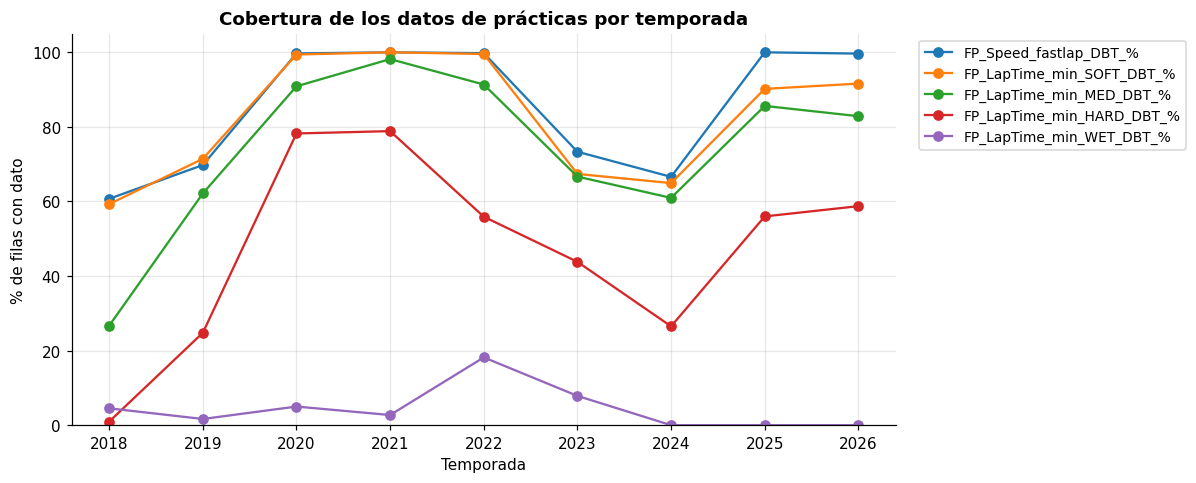

In [ ]:
cols_cob = ["FP_Speed_fastlap_DBT_%", "FP_LapTime_min_SOFT_DBT_%", "FP_LapTime_min_MED_DBT_%",
            "FP_LapTime_min_HARD_DBT_%", "FP_LapTime_min_WET_DBT_%"]
cob = df.groupby("Year")[cols_cob].apply(lambda g: g.notna().mean() * 100)
cob.index = cob.index.astype(str)
mostrar(cob, "Cobertura por temporada (% de filas con dato)", decimales=1, gradiente=cols_cob)

fig, ax = plt.subplots(figsize=(11, 4.5))
cob.plot(ax=ax, marker="o")
ax.set_title("Cobertura de los datos de prácticas por temporada")
ax.set_xlabel("Temporada")
ax.set_ylabel("% de filas con dato")
ax.set_ylim(0, 105)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

**Lectura:** 2021 tiene la telemetría completa (**100%**) y 2020, 2022 y 2025 pasan el
**93%**. Las temporadas con menos datos son 2018 (**60,7%**), 2024 (**62,4%**), 2019 (**66,4%**)
y 2023 (**74,5%**). El caso más marcado es HARD en 2018: solo **1%** de cobertura. WET no aparece
en 2024–2026. Cualquier columna de prácticas que entre al modelo va a tener más huecos en esas
temporadas.

### Ceros que en realidad son faltantes

El caso de la grilla en 0 ya apareció. Quedan por contar los otros ceros que no son datos
reales: las posiciones de campeonato en la primera fecha y la telemetría sin registro.

In [ ]:
conteo_ceros = {
    "Q_GridPosition": int((df_raw["Q_GridPosition"] == 0).sum()),
    "DriverPosition_Before": int((df_raw["DriverPosition_Before"] == 0).sum()),
    "TeamPosition_Before": int((df_raw["TeamPosition_Before"] == 0).sum()),
}
conteo_ceros.update({c: int((df_raw[c] == 0).sum()) for c in tel_abs if (df_raw[c] == 0).any()})
tabla_ceros = pd.DataFrame({
    "Ceros antes (raw)": conteo_ceros,
    "Ceros después (limpio)": {c: int((df[c] == 0).sum()) for c in conteo_ceros},
})
tabla_ceros.loc["TOTAL"] = tabla_ceros.sum()
mostrar(tabla_ceros, "Ceros que se pasaron a nulo en la limpieza")

,Ceros antes (raw),Ceros después (limpio)
Q_GridPosition,45,0
DriverPosition_Before,182,0
TeamPosition_Before,182,0
FP_Throttle_fastlap_ABS,13,0
FP_Speed_fastlap_ABS,24,0
FP_Speed_max_ABS,24,0
FP_RPM_fastlap_ABS,18,0
FP_Brake_fastlap_ABS,17,0
FP_Throttle_mean_MED_ABS,14,0
FP_Speed_mean_MED_ABS,21,0


**Lectura:** la limpieza pasó a nulo **45** grillas, **182** posiciones de piloto y **182** de
equipo (primera fecha) y **153** lecturas de telemetría repartidas en 9 columnas. Sobre 3.744
filas son proporciones chicas (la grilla, 1,2%): eliminarlas o completarlas no cambia las
conclusiones.

### Variables fuertes pero inestables: TeamId y DriverId

`TeamId` y `DriverId` son las variables más fuertes (η² 0,324 y 0,279), pero la fuerza de un
equipo o de un piloto **cambia con los años**. En este período, Red Bull ganó cuatro títulos con
Verstappen y después perdió la punta. Un modelo que usa `TeamId` aprende "red_bull = adelante", y
eso no se sostiene en las temporadas siguientes. La tabla y el gráfico lo muestran.

,Mejor equipo del año,Posición media · mercedes,Posición media · red_bull,Posición media · mclaren,Posición media · Verstappen,η² TeamId,η² DriverId
Year,,,,,,,
2018,mercedes,"3,86","7,64","12,76","6,10","0,38","0,41"
2019,mercedes,"3,24","6,26","10,69","5,00","0,45","0,46"
2020,mercedes,"3,74","7,71","8,62","7,12","0,38","0,41"
2021,mercedes,"5,41","5,84","7,80","4,14","0,43","0,46"
2022,red_bull,"5,52","4,45","10,64","3,50","0,39","0,42"
2023,red_bull,"7,24","3,64","9,74","1,29","0,37","0,43"
2024,mclaren,"6,85","6,62","4,71","3,62","0,48","0,53"
2025,mclaren,"7,20","8,15","4,30","3,78","0,32","0,41"
2026,mercedes,"4,96","9,12","8,19","8,92","0,44","0,47"


Un equipo cambia en promedio 1,56 posiciones de un año al siguiente (n = 63 pares equipo-año).


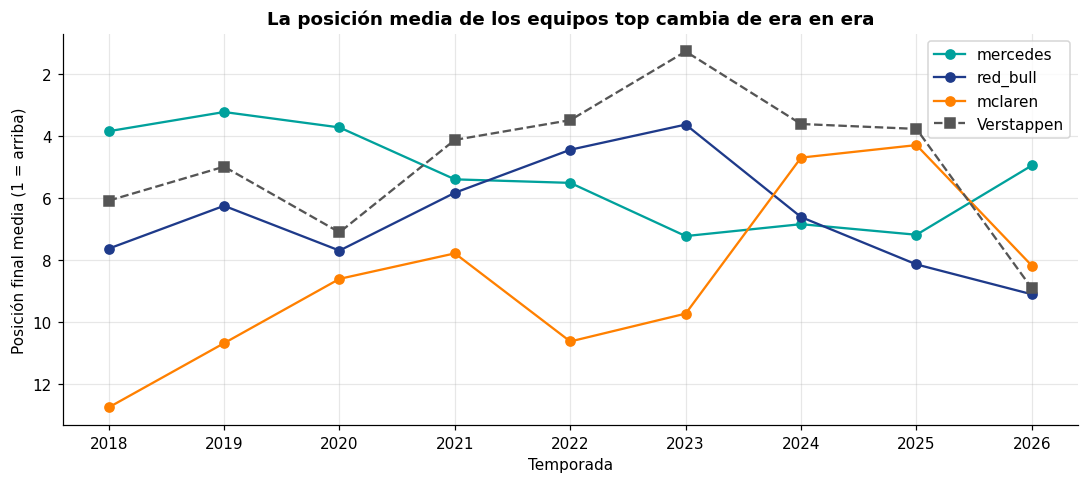

In [ ]:
mejor_equipo = df.groupby("Year").apply(
    lambda g: g.groupby("TeamId")[target].mean().idxmin(), include_groups=False)
equipos = ["mercedes", "red_bull", "mclaren"]
por_equipo = df[df.TeamId.isin(equipos)].groupby(["Year", "TeamId"])[target].mean().unstack()[equipos]
verstappen = df[df.DriverId == "max_verstappen"].groupby("Year")[target].mean()

tabla_drift = pd.DataFrame({"Mejor equipo del año": mejor_equipo})
tabla_drift = tabla_drift.join(por_equipo.add_prefix("Posición media · "))
tabla_drift["Posición media · Verstappen"] = verstappen
tabla_drift["η² TeamId"] = [eta2(g[target], g.TeamId) for _, g in df.groupby("Year")]
tabla_drift["η² DriverId"] = [eta2(g[target], g.DriverId) for _, g in df.groupby("Year")]
tabla_drift.index = tabla_drift.index.astype(str)
mostrar(tabla_drift, "El dominio cambia de equipo según la temporada")

ty = df.groupby(["TeamId", "Year"])[target].mean().unstack()
cambios = []
for yr in range(2018, 2025):
    if yr in ty.columns and yr + 1 in ty.columns:
        cambios.extend((ty[yr + 1] - ty[yr]).dropna().tolist())
print(f"Un equipo cambia en promedio {np.mean(np.abs(cambios)):.2f} posiciones de un año al siguiente "
      f"(n = {len(cambios)} pares equipo-año).".replace(".", ",", 1))

fig, ax = plt.subplots(figsize=(10, 4.5))
for eq, color in zip(equipos, ["#00A19C", "#1E3A8A", "#FF8000"]):
    ax.plot(por_equipo.index, por_equipo[eq], marker="o", color=color, label=eq)
ax.plot(verstappen.index, verstappen, marker="s", linestyle="--", color="#555", label="Verstappen")
ax.invert_yaxis()
ax.set_xlabel("Temporada")
ax.set_ylabel("Posición final media (1 = arriba)")
ax.set_title("La posición media de los equipos top cambia de era en era")
ax.legend()
plt.tight_layout()
plt.show()

**Lectura:** el mejor equipo cambia tres veces: Mercedes (2018–2021), Red Bull (2022–2023),
McLaren (2024–2025) y otra vez Mercedes (2026). Red Bull pasa de una posición media de **3,57** en
2023 a **9,12** en 2026, y Verstappen de **1,27** a **8,92**. En promedio, un equipo se mueve
**1,56 posiciones** de un año al otro. El modelo se va a usar para predecir carreras futuras, así
que `TeamId` y `DriverId` **salen como columnas**: si no, el modelo aprende quién fue campeón en
este período. La forma del momento la capturan mejor las variables del campeonato, que se
recalculan en cada fecha.

### ¿Y la posición del equipo en el campeonato?

`TeamPosition_Before` se recalcula en cada GP, así que no tiene el problema de `TeamId`. Pero
antes de conservarla hay que ver cuánto agrega sobre la del piloto: si se parecen casi
perfecto, sobra.

In [ ]:
pares_equipo = [
    ("TeamPosition_Before", "DriverPosition_Before"),
    ("TeamPosition_Before", "DriverPoints_Before_DBT_%"),
    ("TeamPoints_Before", "DriverPoints_Before"),
]
filas = []
for a, b in pares_equipo:
    d = df[[a, b]].dropna()
    filas.append({"Equipo": a, "Piloto": b, "Spearman": d[a].corr(d[b], method="spearman"), "n": len(d)})
mostrar(pd.DataFrame(filas).set_index(["Equipo", "Piloto"]), "Columnas de equipo contra las del piloto",
        decimales=3)

**Lectura:** la posición del equipo correlaciona **0,906** con la del piloto y **0,892** con la
distancia en puntos al líder; los puntos del equipo, **0,954** con los del piloto. La información
del equipo ya está en las columnas del piloto, así que salen las de equipo y se queda la del
piloto.

### Fuga de datos

¿Hay alguna columna que describa la carrera y que el modelo no tendría antes de la largada?

In [ ]:
post_carrera = [c for c in df.columns if c.startswith("RACE_")]
mostrar(pd.DataFrame({"Valor": {
    "Columnas que describen la carrera": ", ".join(post_carrera),
    "Columnas disponibles antes de la carrera": f"{df.shape[1] - len(post_carrera)} de {df.shape[1]}",
}}), "Chequeo de fuga")

,Valor
Columnas que describen la carrera,RACE_Position
Columnas disponibles antes de la carrera,58 de 59


**Lectura:** la única columna de carrera es el objetivo (`RACE_Position`). `Race_Points`,
`Race_Laps` y `Race_Status` existían en la versión vieja del CSV y ya se quitaron. Las columnas
`_Before` se calculan con el campeonato previo a la fecha.

## Sección 5: Las hipótesis

### Las dos preguntas

Toda hipótesis de esta unidad nace de una de dos preguntas:

- **Qué queremos responder:** la pregunta deportiva, qué determina el resultado de un GP.
  Termina en una **conclusión**.
- **Qué queremos predecir:** la pregunta de modelado, qué columnas usar para predecir
  `RACE_Position`. Termina en una **decisión sobre columnas**.

Se resuelven **siete fichas**. H1 y H2 responden. H3 a H7 deciden columnas. H5, H6 y H7
trabajan juntas sobre el ritmo de prácticas: si SOFT y MED son redundantes (H5), si el desgaste
cambia cuál de los dos importa (H6) y si el desgaste predice por sí solo (H7). De ahí sale si
las dos columnas de desgaste entran al modelo.

### Cómo se arma cada ficha

Una hipótesis no se contesta con un gráfico: se contesta con **un número**, y el gráfico explica
ese número. Cada ficha tiene seis campos, en este orden:

1. **La afirmación:** una oración que puede ser falsa y nombra las columnas.
2. **Qué espero ver:** escrito antes de correr la medida, con lo que ya sabíamos del EDA.
3. **Cómo la mido:** qué plantilla es, qué medida le corresponde y qué gráfico va.
4. **Qué encontré:** el número, su zona del semáforo y el gráfico que lo explica.
5. **Qué movimiento hice:** solo si dio amarillo; si no, "ninguno".
6. **Qué hago con eso:** la decisión concreta sobre el modelo.

La forma de la afirmación define la medida:

| Plantilla | Se escribe | Medida |
|---|---|---|
| Comparación | «*X* difiere entre *A* y *B*» | separación estandarizada (dos grupos) o η² (varios grupos) |
| Asociación | «*X* se mueve junto con *Y*» | Pearson, Spearman y la brecha entre ambos |
| Composición | «*C* está sobrerrepresentada en *G*» | proporción del grupo contra la global |

Los cortes del semáforo están fijados de antemano. Con **3.744 filas**, casi cualquier diferencia
da "estadísticamente significativa". Por eso el semáforo no pregunta si el efecto existe: pregunta
si es lo bastante grande como para cambiar una decisión.

| Medida | Rojo | Amarillo | Verde |
|---|---|---|---|
| Separación estandarizada | < 0,2 | 0,2 – 0,8 | > 0,8 |
| η² | < 0,05 | 0,05 – 0,25 | > 0,25 |
| Correlación (\|ρ\|) | < 0,20 | 0,20 – 0,60 | > 0,60 |
| Brecha (Spearman − Pearson) | < 0,05 | 0,05 – 0,15 | > 0,15 |

**Verde** y **rojo** cierran la hipótesis. **Amarillo** permite un **movimiento**, y es el
gráfico el que dice cuál: partir la población, controlar una tercera variable o cambiar la
escala. Hay un tope de **dos movimientos**: si después sigue en amarillo, la conclusión es
*inconclusa*.

Tres herramientas que se usan en las fichas, explicadas corto:

- **Brecha Spearman − Pearson:** Spearman mide si las dos variables van en el mismo orden;
  Pearson, si siguen una línea recta. Si la brecha es grande, la relación existe pero es curva
  (o unos pocos valores extremos arrastran a Pearson).
- **Correlación parcial:** la relación que queda entre *X* y el resultado después de descontar
  lo que ya explica una tercera variable (por ejemplo, la grilla). Si cae a rojo, *X* no tenía
  nada propio: repetía a la tercera variable.
- **Separación estandarizada:** la diferencia de medias entre dos grupos, dividida por el desvío
  típico. Dice si los grupos están lejos en comparación con cuánto varían por dentro.

In [ ]:
CORTES = {"separacion": (0.2, 0.8), "eta2": (0.05, 0.25),
          "correlacion": (0.2, 0.6), "brecha": (0.05, 0.15)}


def semaforo(valor, medida):
    bajo, alto = CORTES[medida]
    v = abs(valor)
    return "rojo" if v < bajo else "verde" if v > alto else "amarillo"


def asociacion(x, y):
    p = x.corr(y)
    s = x.corr(y, method="spearman")
    return {"Pearson": p, "Spearman": s, "Brecha": s - p}


def parcial(data, x, y, controles):
    # Correlación parcial de rangos: correlación entre x e y después de descontarles
    # (por regresión sobre los rangos) lo que explican las variables de control.
    d = data[[x, y] + controles].dropna()
    if len(d) < 10:
        return np.nan, len(d)
    rx, ry = d[x].rank(), d[y].rank()
    C = np.column_stack([d[c].rank() for c in controles] + [np.ones(len(d))])
    ex = rx - C @ np.linalg.lstsq(C, rx, rcond=None)[0]
    ey = ry - C @ np.linalg.lstsq(C, ry, rcond=None)[0]
    return np.corrcoef(ex, ey)[0, 1], len(d)


def separacion(valores, en_grupo):
    # Separación estandarizada entre dos grupos: diferencia de medias / desvío combinado.
    a, b = valores[en_grupo].dropna(), valores[~en_grupo].dropna()
    desvio = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / desvio, len(a), len(b)


def tabla_medidas(filas, titulo):
    # filas: lista de (medida, valor, tipo de corte o None). Agrega la zona del semáforo.
    t = pd.DataFrame([{"Medida": m, "Valor": v, "Zona": semaforo(v, c) if c else "—"}
                      for m, v, c in filas]).set_index("Medida")
    mostrar(t, titulo, decimales=3, zonas=["Zona"])

## 5.1 Hipótesis para responder

### H1 · La grilla manda

**Pregunta:** responder · **Plantilla:** asociación

**1. La afirmación.** `Q_GridPosition` y `RACE_Position` se mueven juntas con fuerza: quien larga
más adelante termina más adelante.

**2. Qué espero ver.** Una correlación positiva y fuerte, y una relación recta: Pearson y
Spearman parecidos.

**3. Cómo la mido.** Es una asociación entre dos posiciones, así que van Pearson, Spearman y la
brecha. Spearman da la fuerza; la brecha dice si la relación es recta o curva. Gráfico: el mapa
grilla × resultado de la Sección 3.

,Valor,Zona
Medida,,
Spearman,"0,625",verde
Pearson,"0,623",—
Brecha (Spearman − Pearson),"0,002",rojo


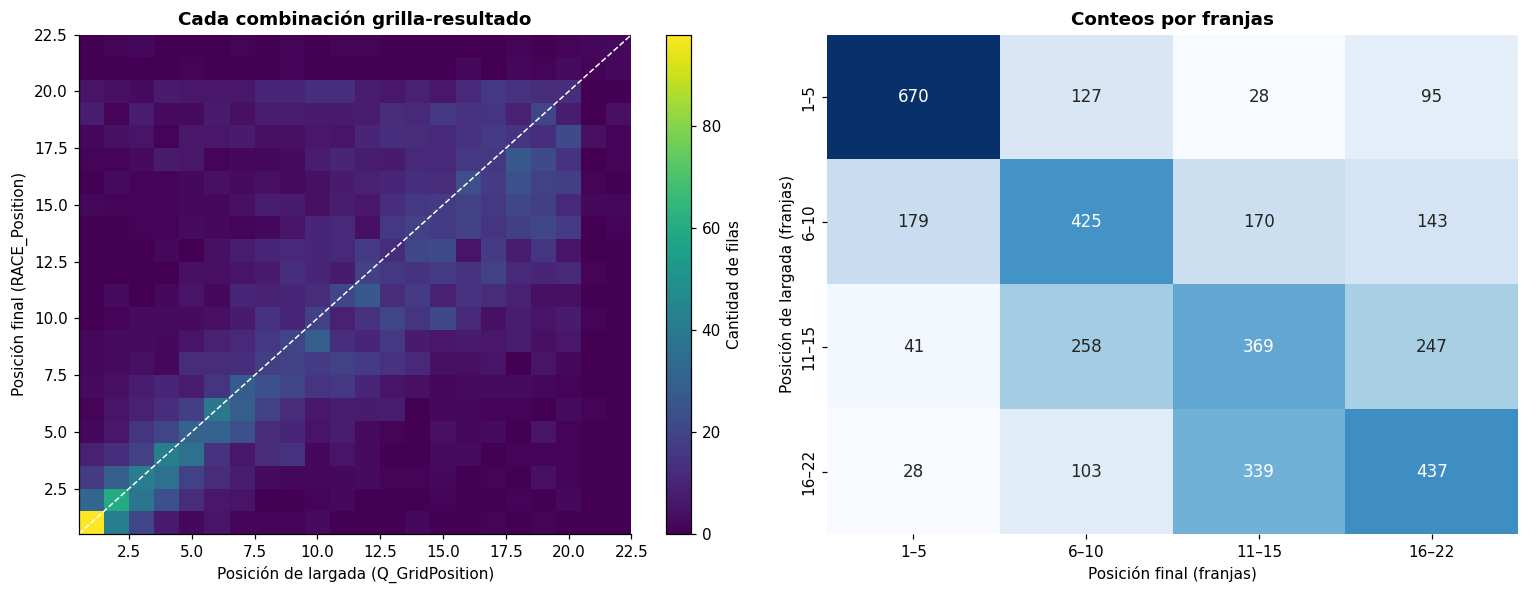

,Valor
Spearman² (parte del orden explicada) %,"39,0"
Largaron 1–5 y terminaron 1–5,670 de 920
Largaron 16–22 y terminaron 16–22,437 de 907


In [ ]:
d = df[["Q_GridPosition", target]].dropna()
h1 = asociacion(d.Q_GridPosition, d[target])
tabla_medidas([
    ("Spearman", h1["Spearman"], "correlacion"),
    ("Pearson", h1["Pearson"], None),
    ("Brecha (Spearman − Pearson)", h1["Brecha"], "brecha"),
], f"H1 · Grilla contra resultado (n = {len(d)})")
grafico_grilla_resultado(d)

**4. Qué encontré.** Spearman **0,625** → **verde**. La brecha es **0,002** → **rojo**: la
relación es recta, no hay curva que corregir. En el gráfico lo más denso está sobre la diagonal:
**679 de 930** que largaron entre los 5 primeros terminaron ahí, y **442 de 917** de los que
largaron del 16 para atrás también terminaron atrás. Hay dispersión, pero el orden se conserva.

**5. Qué movimiento hice.** Ninguno (verde).

**6. Qué hago con eso.** **Confirmada.** `Q_GridPosition` entra al modelo como **variable base
obligatoria**. `Q_Position` sale: es casi igual a la grilla (0,961) y no tiene las
penalizaciones aplicadas.

### H2 · Una sola vuelta resume la clasificación

**Pregunta:** responder · **Plantilla:** asociación

**1. La afirmación.** `Q_Best_seconds_DBT_%` se asocia con `RACE_Position`, y
`Q1_seconds_DBT_%`, `Q2_seconds_DBT_%` y `Q3_seconds_DBT_%` no agregan nada sobre ella: la mejor
vuelta de la clasificación vale por las tres tandas.

**2. Qué espero ver.** Una correlación positiva con el resultado (más lejos del mejor, peor
posición) y las tres tandas moviéndose casi igual que Q_Best.

**3. Cómo la mido.** Son dos asociaciones, una por cada parte de la afirmación:

- **(a)** Q_Best contra el resultado: Spearman, Pearson y brecha.
- **(b)** Cada tanda contra Q_Best (Spearman) y, para ver si agrega algo, la **parcial** de cada
  tanda con el resultado descontando Q_Best. Si la tanda no agrega, la parcial da rojo.

Gráficos: Q_Best contra el resultado, y Q3 contra Q_Best. Se usa la versión DBT (Sección 3).

,Valor,Zona
Medida,,
Spearman,"0,585",amarillo
Pearson,"0,377",—
Brecha (Spearman − Pearson),"0,208",verde


,n,Spearman con Q_Best,Zona (se parece),"Parcial con resultado, sin Q_Best",Zona (agrega)
Tanda,,,,,
Q3_seconds_DBT_%,1795,"0,948",verde,"0,118",rojo
Q2_seconds_DBT_%,2726,"0,859",verde,"0,064",rojo
Q1_seconds_DBT_%,3653,"0,814",verde,"0,012",rojo


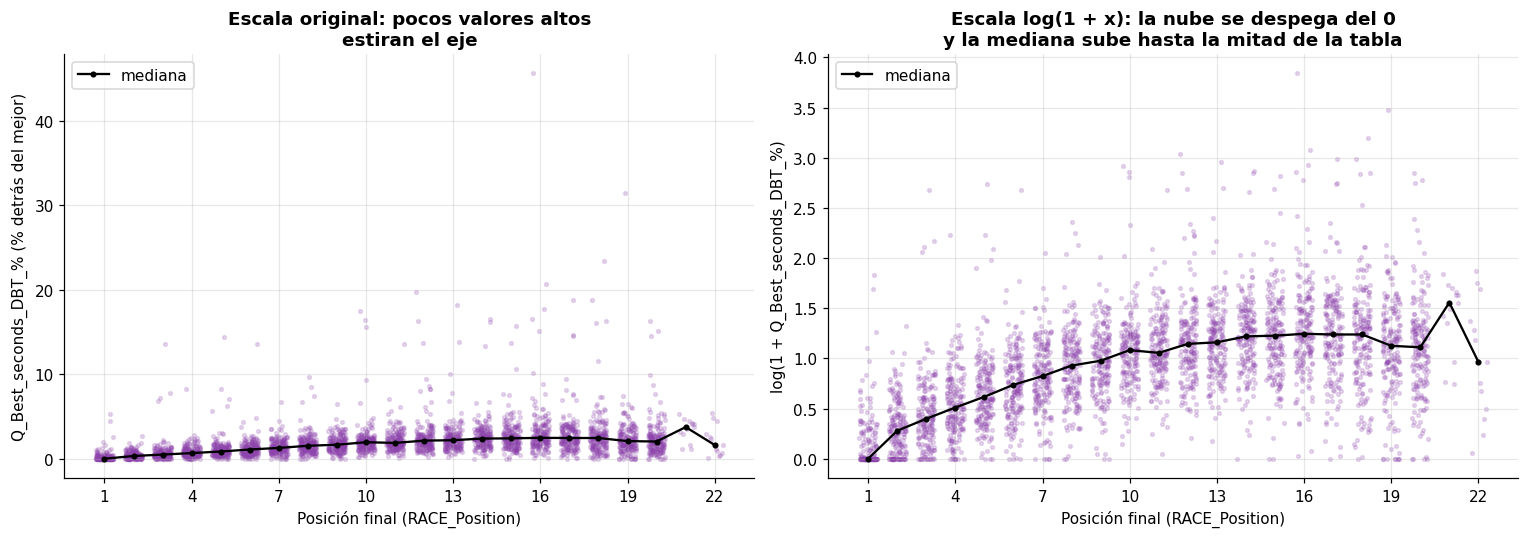

In [ ]:
d = df[["Q_Best_seconds_DBT_%", target]].dropna()
h2a = asociacion(d["Q_Best_seconds_DBT_%"], d[target])
tabla_medidas([
    ("Spearman", h2a["Spearman"], "correlacion"),
    ("Pearson", h2a["Pearson"], None),
    ("Brecha (Spearman − Pearson)", h2a["Brecha"], "brecha"),
], f"H2 (a) · Q_Best contra resultado (n = {len(d)})")

filas = []
for q in ["Q3_seconds_DBT_%", "Q2_seconds_DBT_%", "Q1_seconds_DBT_%"]:
    dq = df[[q, "Q_Best_seconds_DBT_%"]].dropna()
    s = dq[q].corr(dq["Q_Best_seconds_DBT_%"], method="spearman")
    p, _ = parcial(df, q, target, ["Q_Best_seconds_DBT_%"])
    filas.append({"Tanda": q, "n": len(dq),
                  "Spearman con Q_Best": s, "Zona (se parece)": semaforo(s, "correlacion"),
                  "Parcial con resultado, sin Q_Best": p, "Zona (agrega)": semaforo(p, "correlacion")})
mostrar(pd.DataFrame(filas).set_index("Tanda"), "H2 (b) · ¿Las tandas agregan algo sobre Q_Best?",
        decimales=3, zonas=["Zona (se parece)", "Zona (agrega)"])

rng = np.random.default_rng(14)
x_jit = d[target] + rng.uniform(-0.3, 0.3, len(d))
medianas = d.groupby(target)["Q_Best_seconds_DBT_%"].median()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(x_jit, d["Q_Best_seconds_DBT_%"], s=6, alpha=0.2, color="#8E44AD")
axes[0].plot(medianas.index, medianas.values, color="black", marker="o", markersize=3, label="mediana")
axes[0].set_title("Escala original: pocos valores altos\nestiran el eje")
axes[0].set_ylabel("Q_Best_seconds_DBT_% (% detrás del mejor)")
axes[1].scatter(x_jit, np.log1p(d["Q_Best_seconds_DBT_%"]), s=6, alpha=0.2, color="#8E44AD")
axes[1].plot(medianas.index, np.log1p(medianas.values), color="black", marker="o", markersize=3,
             label="mediana")
axes[1].set_title("Escala log(1 + x): la nube se despega del 0\ny la mediana sube hasta la mitad de la tabla")
axes[1].set_ylabel("log(1 + Q_Best_seconds_DBT_%)")
for ax in axes:
    ax.set_xlabel("Posición final (RACE_Position)")
    ax.set_xticks(range(1, 23, 3))
    ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**4. Qué encontré.**

- **(a)** Spearman **0,585** → **amarillo**. Pearson **0,377** y brecha **0,208** → **verde**: la
  relación existe, pero la recta la capta mal. En el panel izquierdo se ve por qué: la mayoría de
  los pilotos está entre 0% y 4% del mejor, y unos pocos valores muy altos (hasta 45%) estiran el
  eje y tiran de Pearson. La mediana sube con la posición hasta más o menos el puesto 13–14 y
  después se aplana; en los últimos puestos hasta baja un poco (el dataset no tiene el motivo de
  cada llegada, así que no se puede saber si son abandonos).
- **(b)** Las tres tandas se mueven casi igual que Q_Best: **0,949** (Q3), **0,860** (Q2) y
  **0,814** (Q1), las tres en **verde**. Ninguna agrega algo propio: sus parciales son **+0,117**,
  **+0,059** y **+0,010**, las tres en **rojo**.

**5. Qué movimiento hice.** Para la parte (a), **cambiar la escala**. El gráfico muestra una nube
que sube de forma ordenada pero aplastada contra el 0, y la brecha es grande: es justo el caso de
este movimiento. Se aplica `log(1 + x)` a Q_Best.

In [ ]:
pearson_log = np.log1p(d["Q_Best_seconds_DBT_%"]).corr(d[target])
tabla_medidas([
    ("Spearman (no cambia con el log)", h2a["Spearman"], "correlacion"),
    ("Pearson sobre log(1 + Q_Best)", pearson_log, None),
    ("Brecha después del movimiento", h2a["Spearman"] - pearson_log, "brecha"),
], "H2 (a) · Después de cambiar la escala")

,Valor,Zona
Medida,,
Spearman (no cambia con el log),"0,585",amarillo
Pearson sobre log(1 + Q_Best),"0,558",—
Brecha después del movimiento,"0,027",rojo


Con la escala logarítmica, Pearson sube a **0,558** y la brecha baja a **0,027** (**rojo**): la
curva era un problema de escala, no de la relación. La fuerza queda en **amarillo** (0,56 a 0,59):
Q_Best anticipa el resultado de forma **moderada**. No se hace un segundo movimiento: el gráfico
no muestra grupos separados ni hay una tercera variable que contradiga algo conocido.

El aplanamiento del final sigue estando en la escala log. Por eso la relación es moderada y no
fuerte: Q_Best ordena bien a los de adelante, pero casi no distingue entre los de atrás.

**Resultado:** la parte **(b)** se **confirma** (verde): una vuelta resume la clasificación. La
parte **(a)** queda en **amarillo**: la relación con el resultado es real pero moderada. Q_Best
no "manda" como la grilla.

**6. Qué hago con eso.** `Q_Best_seconds_DBT_%` entra como **única columna de clasificación**
(además de la grilla). **Hay que transformarla** con `log(1 + x)` si el modelo es lineal; a un
modelo de árboles la escala no le cambia nada. `Q1_seconds_DBT_%`, `Q2_seconds_DBT_%` y
`Q3_seconds_DBT_%` **salen**: repiten a Q_Best y no agregan nada. Sus versiones ABS ya habían
salido por la regla ABS vs DBT.

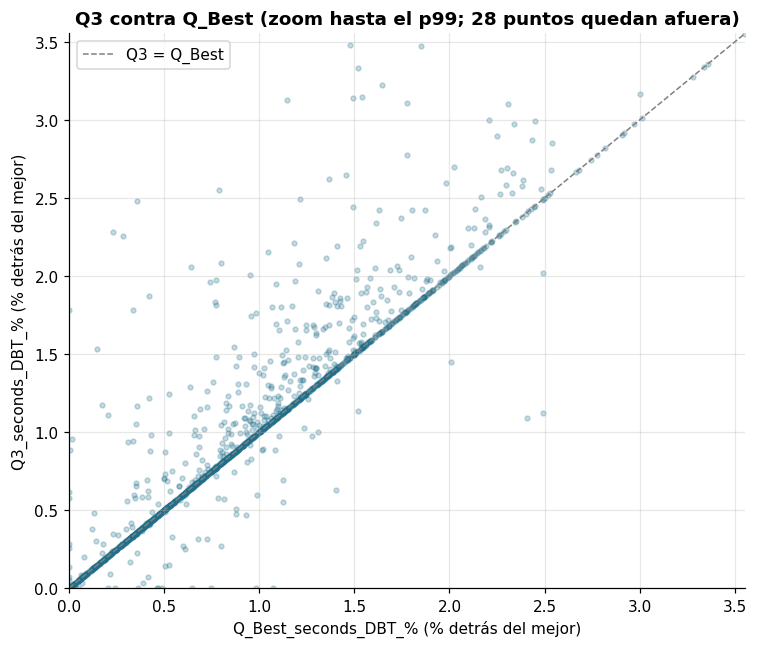

Filas donde la mejor vuelta NO fue la de Q3: 24,3%


In [ ]:
dq3 = df[["Q_Best_seconds_DBT_%", "Q3_seconds_DBT_%"]].dropna()
tope = np.percentile(dq3.values, 99)
fuera = int((dq3 > tope).any(axis=1).sum())
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(dq3["Q_Best_seconds_DBT_%"], dq3["Q3_seconds_DBT_%"], alpha=0.25, s=10, color="#1F6F8B")
ax.plot([0, tope], [0, tope], "--", color="gray", linewidth=1, label="Q3 = Q_Best")
ax.set_xlim(0, tope)
ax.set_ylim(0, tope)
ax.set_xlabel("Q_Best_seconds_DBT_% (% detrás del mejor)")
ax.set_ylabel("Q3_seconds_DBT_% (% detrás del mejor)")
ax.set_title(f"Q3 contra Q_Best (zoom hasta el p99; {fuera} puntos quedan afuera)")
ax.legend()
plt.tight_layout()
plt.show()

q_abs = df[["Q_Best_seconds_ABS", "Q3_seconds_ABS"]].dropna()
print(f"Filas donde la mejor vuelta NO fue la de Q3: "
      f"{(q_abs.Q3_seconds_ABS > q_abs.Q_Best_seconds_ABS).mean() * 100:.1f}%".replace(".", ","))

**Qué se ve.** Los puntos se pegan a la diagonal. Para el **76%** de los que llegaron a Q3, la
mejor vuelta *es* la de Q3. El otro **24%** hizo su mejor tiempo en Q1 o Q2 y no lo mejoró en
Q3: son los puntos que se separan de la diagonal.

## 5.2 Hipótesis para predecir

### H3

La velocidad de la vuelta rápida anticipa el resultado
**Pregunta:** predecir · **Plantilla:** asociación

**1. La afirmación.** `FP_Speed_fastlap_DBT_%` se asocia con `RACE_Position`: los autos más
rápidos en prácticas terminan más adelante.

**2. Qué espero ver.** Una correlación negativa moderada: más velocidad, número de posición más
chico.

**3. Cómo la mido.** Asociación: Spearman, Pearson y brecha. Se usa la versión DBT porque es la
comparable entre circuitos (Sección 3). Gráfico: la velocidad según la posición de largada.

In [ ]:
d = df[["FP_Speed_fastlap_DBT_%", target]].dropna()
h3 = asociacion(d["FP_Speed_fastlap_DBT_%"], d[target])
tabla_medidas([
    ("Spearman", h3["Spearman"], "correlacion"),
    ("Pearson", h3["Pearson"], None),
    ("Brecha (Spearman − Pearson)", h3["Brecha"], "brecha"),
], f"H3 · Velocidad contra resultado (n = {len(d)})")

,Valor,Zona
Medida,,
Spearman,"0,399",amarillo
Pearson,"0,067",—
Brecha (Spearman − Pearson),"0,332",verde


**4. Qué encontré.** Spearman **−0,303** → **amarillo**. Pearson da **0,000** y la brecha es
**−0,303** (**verde**). Pearson se anula por los valores absurdos de hasta 3.583% que se vieron
en la Sección 2: unos pocos puntos gigantes rompen la recta. Spearman trabaja con el orden y no
se deja arrastrar por eso. La relación existe en el orden, pero es moderada. Como es amarillo,
toca un movimiento. Para elegirlo se mira la velocidad contra la grilla:

,Valor,Zona
Medida,,
Spearman velocidad ~ grilla,"0,508",amarillo


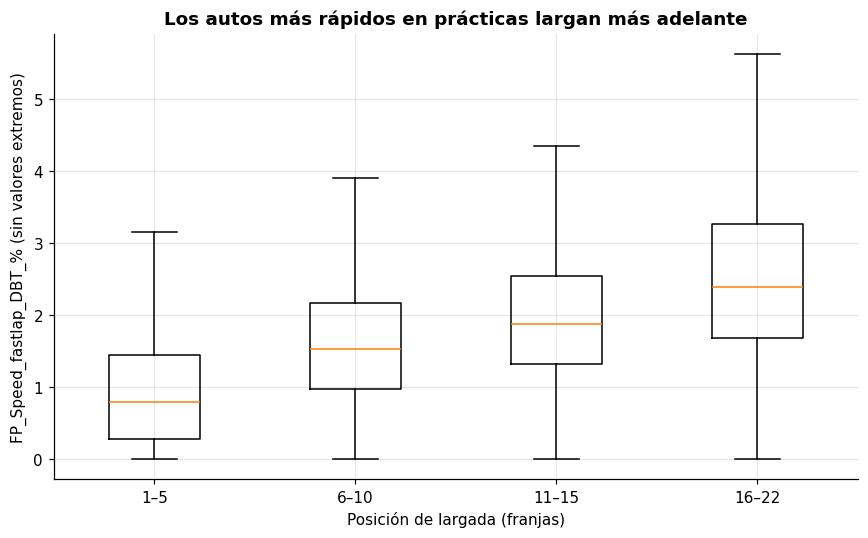

In [ ]:
d2 = df[["FP_Speed_fastlap_DBT_%", "Q_GridPosition"]].dropna()
s_vel_grilla = d2["FP_Speed_fastlap_DBT_%"].corr(d2.Q_GridPosition, method="spearman")
tabla_medidas([("Spearman velocidad ~ grilla", s_vel_grilla, "correlacion")],
              f"H3 · ¿La velocidad acompaña a la grilla? (n = {len(d2)})")

franja_grilla = pd.cut(d2.Q_GridPosition, FRANJAS, labels=NOMBRES_FRANJAS)
fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot([d2.loc[franja_grilla == f, "FP_Speed_fastlap_DBT_%"] for f in NOMBRES_FRANJAS],
           tick_labels=NOMBRES_FRANJAS, showfliers=False)
ax.set_xlabel("Posición de largada (franjas)")
ax.set_ylabel("FP_Speed_fastlap_DBT_% (sin valores extremos)")
ax.set_title("Los autos más rápidos en prácticas largan más adelante")
plt.tight_layout()
plt.show()

**Qué se ve.** La velocidad baja franja a franja a medida que la largada empeora (Spearman
**−0,399**). Y la grilla es la variable que mejor predice el resultado (H1). Es un caso típico de
**tercera variable**: los autos rápidos clasifican adelante y por eso terminan adelante. Puede
que la velocidad no agregue nada propio.

**5. Qué movimiento hice.** **Controlar una tercera variable: la grilla.** Si la velocidad agrega
algo por encima de la largada, la correlación parcial tiene que seguir en amarillo o en verde. Se
mide de dos formas: sobre todo el dataset y **carrera por carrera** (comparando solo pilotos de
la misma carrera y promediando).

In [ ]:
p_global, n_global = parcial(df, "FP_Speed_fastlap_DBT_%", target, ["Q_GridPosition"])
vals = df.groupby(["Year", "RoundNumber"]).apply(
    lambda g: parcial(g, "FP_Speed_fastlap_DBT_%", target, ["Q_GridPosition"])[0],
    include_groups=False).dropna()
tabla_medidas([
    (f"Parcial global, sin la grilla (n = {n_global})", p_global, "correlacion"),
    (f"Parcial carrera por carrera, promedio ({len(vals)} carreras)", vals.mean(), "correlacion"),
], "H3 · Velocidad contra resultado, descontando la grilla")

,Valor,Zona
Medida,,
"Parcial global, sin la grilla (n = 3096)","0,129",rojo
"Parcial carrera por carrera, promedio (158 carreras)","0,163",rojo


**Resultado del movimiento.** Al controlar la grilla de salida, la correlación parcial global es 0,129 y el promedio de las correlaciones parciales por carrera es 0,163. Ambos valores quedan en zona roja según los umbrales definidos. Esto sugiere que la brecha de velocidad mantiene una asociación débil con el resultado final una vez considerada la grilla.

**6. Qué hago con eso.** **Refutada.** Sale **todo el bloque de telemetría** (las 9 columnas DBT
y las 9 ABS). Si la mejor columna del bloque no agrega nada sobre la grilla, las que la copian
tampoco. Esto no se veía mirando solo la versión absoluta, como en la versión anterior del EDA.

### H4 · El contexto de la fecha no aporta

**Pregunta:** predecir · **Plantilla:** asociación

**1. La afirmación.** `Year`, `RoundNumber`, `Races_Before`, `FinishRate_Before` y
`Avg_Position_Gain_Before` **no** se asocian con `RACE_Position` (todas en rojo).

**2. Qué espero ver.** Correlaciones cerca de cero: son variables de contexto, no de
rendimiento. Quizás la regularidad (`FinishRate_Before`) algo más.

**3. Cómo la mido.** Asociación de cada una con el resultado: Spearman, Pearson y brecha. Si
alguna aporta, tiene que verse acá. Gráfico: barras con el Spearman de cada una, con la zona roja
marcada.

,n,Pearson,Spearman,Brecha,Zona
Variable,,,,,
Year,3704,"0,020","0,019","-0,002",rojo
RoundNumber,3704,"-0,008","-0,007","0,001",rojo
Races_Before,3704,"-0,022","-0,021","0,001",rojo
FinishRate_Before,3509,"-0,134","-0,154","-0,020",rojo
Avg_Position_Gain_Before,3509,"0,165","0,175","0,009",rojo


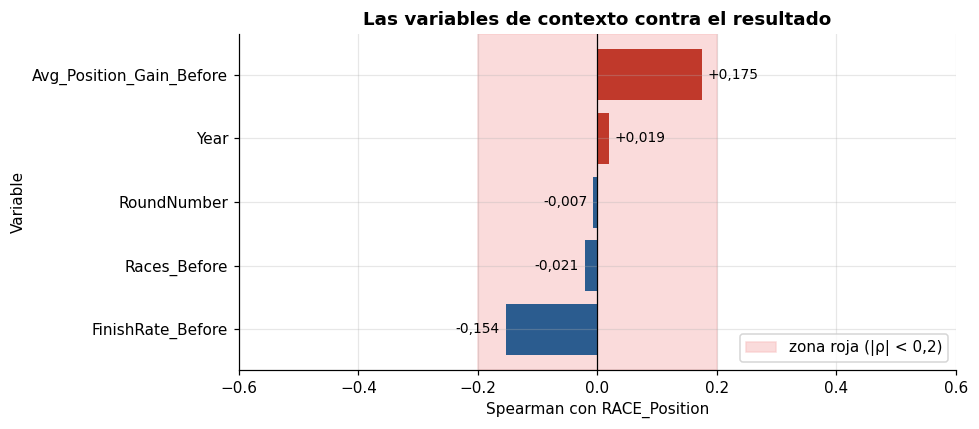

In [ ]:
filas = []
for c in ["Year", "RoundNumber", "Races_Before", "FinishRate_Before", "Avg_Position_Gain_Before"]:
    d = df[[c, target]].dropna()
    a = asociacion(d[c], d[target])
    filas.append({"Variable": c, "n": len(d), **a, "Zona": semaforo(a["Spearman"], "correlacion")})
h4 = pd.DataFrame(filas).set_index("Variable")
mostrar(h4, "H4 · Variables de contexto contra resultado", decimales=3, zonas=["Zona"])

top = h4.Spearman.sort_values()
fig, ax = plt.subplots(figsize=(9, 4))
ax.axvspan(-0.2, 0.2, color=COLORES_ZONA["rojo"], alpha=0.6, label="zona roja (|ρ| < 0,2)")
ax.barh(top.index, top.values, color=["#2B5C8F" if v < 0 else "#c0392b" for v in top])
for i, v in enumerate(top.values):
    ax.text(v + (0.01 if v >= 0 else -0.01), i, f"{v:+.3f}".replace(".", ","),
            va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(-0.6, 0.6)
ax.set_xlabel("Spearman con RACE_Position")
ax.set_ylabel("Variable")
ax.set_title("Las variables de contexto contra el resultado")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**4. Qué encontré.** Las cinco en **rojo**: `Year` **0,018**, `RoundNumber` **−0,007**,
`Races_Before` **−0,022**, `FinishRate_Before` **−0,154** y `Avg_Position_Gain_Before` **0,175**.
Las dos de regularidad son las que más se acercan al corte, pero ninguna llega a 0,2. Además,
`RoundNumber` y `Races_Before` son casi la misma columna (**0,969**).

**5. Qué movimiento hice.** Ninguno (rojo).

**6. Qué hago con eso.** **Confirmada** (no aportan). Salen las cinco como columnas del modelo.
`Year` y `RoundNumber` se conservan solo como identificadores, para separar entrenamiento y
prueba por fecha.

### H5 · SOFT y MED miden lo mismo

**Pregunta:** predecir · **Plantilla:** asociación

**1. La afirmación.** `FP_LapTime_min_SOFT_DBT_%` y `FP_LapTime_min_MED_DBT_%` miden el mismo
ritmo: se mueven casi igual (correlación en verde), así que al modelo le alcanza con una.

**2. Qué espero ver.** Una correlación alta: un auto rápido con blandos debería serlo también con
medios.

**3. Cómo la mido.** Asociación entre las dos columnas: Spearman, Pearson y brecha. Para
descartar una por redundante hace falta **verde**. Como apoyo, la parcial de cada una con el
resultado descontando la otra: dice si cada compuesto tiene algo propio. Gráfico: SOFT contra
MED.

,Valor,Zona
Medida,,
Spearman SOFT ~ MED,"0,537",amarillo
Pearson SOFT ~ MED,"0,199",—
Brecha (Spearman − Pearson),"0,338",verde


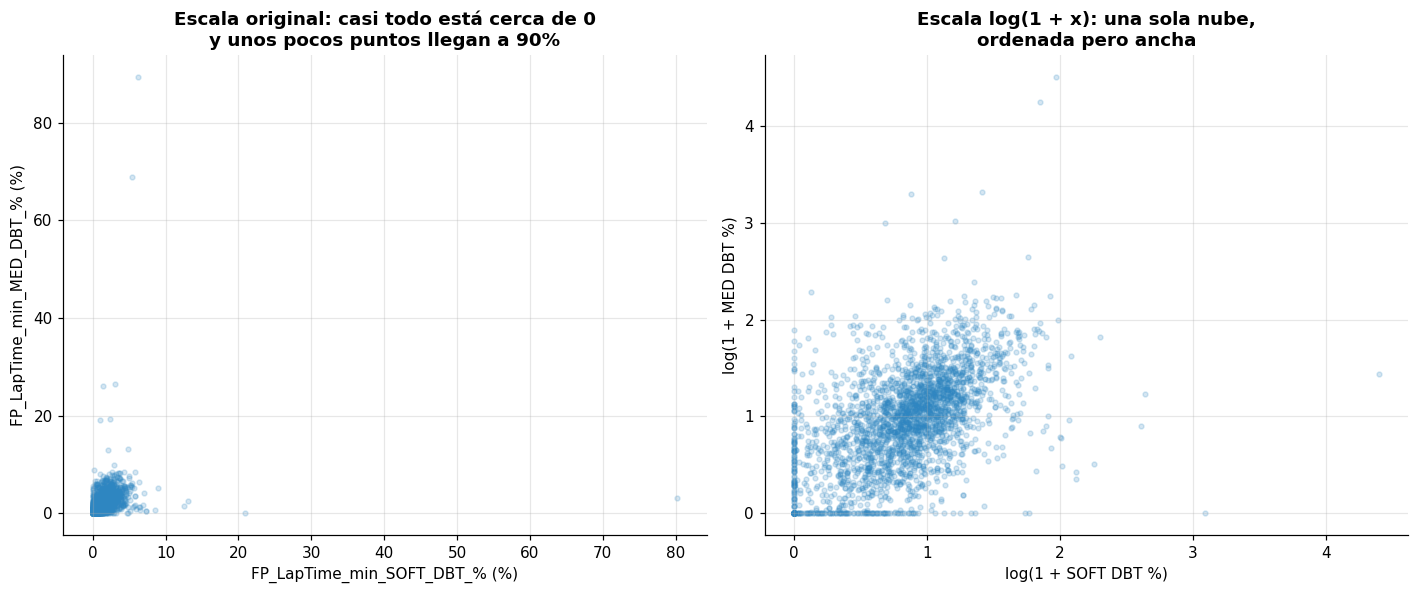

In [ ]:
S, M = "FP_LapTime_min_SOFT_DBT_%", "FP_LapTime_min_MED_DBT_%"
d = df[[S, M]].dropna()
h5 = asociacion(d[S], d[M])
tabla_medidas([
    ("Spearman SOFT ~ MED", h5["Spearman"], "correlacion"),
    ("Pearson SOFT ~ MED", h5["Pearson"], None),
    ("Brecha (Spearman − Pearson)", h5["Brecha"], "brecha"),
], f"H5 · SOFT contra MED (n = {len(d)} filas con los dos compuestos)")

tope = np.percentile(d.values, 99)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
axes[0].scatter(d[S], d[M], alpha=0.2, s=10, color="#2E86C1")
axes[0].set_xlabel("FP_LapTime_min_SOFT_DBT_% (%)")
axes[0].set_ylabel("FP_LapTime_min_MED_DBT_% (%)")
axes[0].set_title("Escala original: casi todo está cerca de 0\ny unos pocos puntos llegan a 90%")
axes[1].scatter(np.log1p(d[S]), np.log1p(d[M]), alpha=0.2, s=10, color="#2E86C1")
axes[1].set_xlabel("log(1 + SOFT DBT %)")
axes[1].set_ylabel("log(1 + MED DBT %)")
axes[1].set_title("Escala log(1 + x): una sola nube,\nordenada pero ancha")
plt.tight_layout()
plt.show()

**4. Qué encontré.** Spearman **0,537** → **amarillo**. Pearson **0,199** y brecha **0,338** →
**verde**. En el panel izquierdo, casi todas las filas están entre 0% y 5% del mejor y unos pocos
puntos llegan al 90%. Esos pocos puntos hunden a Pearson.

**5. Qué movimiento hice.** **Cambiar la escala.** La brecha es grande y la nube está aplastada
contra el 0 por los valores extremos, que es lo que pide este movimiento. Se aplica
`log(1 + x)` a las dos columnas (panel derecho).

In [ ]:
pearson_log = np.log1p(d[S]).corr(np.log1p(d[M]))
tabla_medidas([
    ("Spearman (no cambia con el log)", h5["Spearman"], "correlacion"),
    ("Pearson sobre log(1 + x)", pearson_log, "correlacion"),
    ("Brecha después del movimiento", h5["Spearman"] - pearson_log, "brecha"),
], "H5 · Después de cambiar la escala")

p_med, n1 = parcial(df, M, target, [S])
p_soft, n2 = parcial(df, S, target, [M])
tabla_medidas([
    ("Parcial de SOFT con el resultado, sin MED", p_soft, "correlacion"),
    ("Parcial de MED con el resultado, sin SOFT", p_med, "correlacion"),
], f"H5 · Apoyo: ¿cada compuesto tiene algo propio? (n = {n1})")

,Valor,Zona
Medida,,
Spearman (no cambia con el log),"0,537",amarillo
Pearson sobre log(1 + x),"0,512",amarillo
Brecha después del movimiento,"0,025",rojo


,Valor,Zona
Medida,,
"Parcial de SOFT con el resultado, sin MED","0,380",amarillo
"Parcial de MED con el resultado, sin SOFT","0,196",rojo


Después del movimiento, Pearson sube a **0,512** y la brecha cae a **0,025** (**rojo**): la curva
era de escala. Pero la fuerza de la relación sigue en **amarillo** (0,25 a 0,26). No hay un
segundo movimiento justificado: en la escala log se ve **una sola nube**, sin grupos que se
separen, y no hay una tercera variable que empuje a las dos.

**Resultado: inconclusa.** SOFT y MED se parecen, pero no lo suficiente para decir que son la
misma medida. Las parciales van en la misma línea: SOFT tiene algo propio sobre MED (**+0,376**,
amarillo); MED sobre SOFT, poco (**+0,197**, rojo por muy poco).

**6. Qué hago con eso.** Para sacar una columna por redundante hacía falta verde, y no llegó.
**Se quedan los dos compuestos:** SOFT como principal (más cobertura y más relación con el
resultado) y MED como complemento. H6 muestra en qué carreras MED pasa a pesar más.

### H6 · El desgaste decide qué compuesto importa

**Pregunta:** predecir · **Plantilla:** comparación (entre grupos)

El dataset no tiene vueltas individuales ni paradas en boxes. El **desgaste** se estima, para
cada compuesto, como cuánto más lenta es la vuelta promedio que la mejor vuelta, en %:

`FP_Desgaste_{SOFT,MED} = (FP_LapTime_mean_ABS − FP_LapTime_min_ABS) / FP_LapTime_min_ABS × 100`

Si el número es alto, el piloto pierde mucho ritmo a lo largo de la tanda con ese compuesto.

**1. La afirmación.** Cuánto se relaciona cada mejor vuelta (`FP_LapTime_min_SOFT_DBT_%` y
`FP_LapTime_min_MED_DBT_%`) con `RACE_Position` **difiere según el desgaste**. Cuando SOFT se
degrada más que MED (`FP_Desgaste_SOFT − FP_Desgaste_MED` alto), la ventaja de SOFT sobre MED
como predictor crece.

**2. Qué espero ver.** Si el desgaste no importara, la ventaja de SOFT sobre MED (ρ SOFT − ρ MED)
sería parecida en todos los grupos. Esperamos que no lo sea: que cambie de un extremo al otro, a
favor de SOFT donde SOFT se degrada más.

**3. Cómo la mido.** Se parten las filas en **cinco grupos del mismo tamaño (quintiles)** según
la diferencia de desgaste entre SOFT y MED. En cada grupo se mide el Spearman de cada mejor
vuelta con el resultado, y la medida es **cuánto cambia la ventaja de SOFT (ρ SOFT − ρ MED) entre
el primer y el último grupo**.

La tabla de la cátedra no tiene una medida para "cuánto cambia una correlación entre grupos". Se
usan los cortes de la **brecha** (0,05 / 0,15), porque la brecha también es una diferencia entre
dos correlaciones. Es un criterio que adapta el grupo y se fija antes de ver el resultado.
Gráfico: barras con el Spearman de cada compuesto en cada grupo.

,n,"Desgaste SOFT − MED, medio (%)",ρ SOFT,ρ MED,Ventaja SOFT (ρ SOFT − ρ MED)
Grupo,,,,,
Q1: MED se degrada más,525,"-2,472","0,446","0,460","-0,015"
Q2,524,"-1,163","0,474","0,406","0,069"
Q3: parecido,524,"-0,263","0,524","0,404","0,120"
Q4,524,"0,614","0,546","0,415","0,132"
Q5: SOFT se degrada más,525,"2,599","0,577","0,418","0,159"


,Valor,Zona
Medida,,
Cambio de la ventaja de SOFT entre Q5 y Q1,"0,174",verde


Remuestreo (500 veces): el 95% de los valores cae entre 0,056 y 0,292


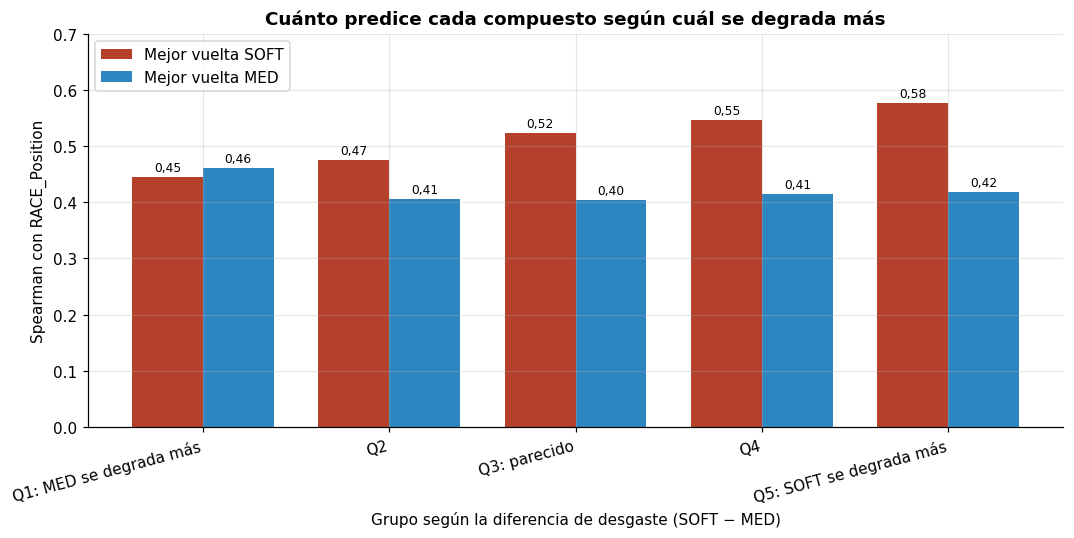

In [ ]:
for comp in ["SOFT", "MED"]:
    df[f"FP_Desgaste_{comp}"] = ((df[f"FP_LapTime_mean_{comp}_ABS"] - df[f"FP_LapTime_min_{comp}_ABS"])
                                 / df[f"FP_LapTime_min_{comp}_ABS"] * 100)
df["dif_desgaste"] = df["FP_Desgaste_SOFT"] - df["FP_Desgaste_MED"]

GRUPOS_DESGASTE = ["Q1: MED se degrada más", "Q2", "Q3: parecido", "Q4", "Q5: SOFT se degrada más"]
quintil = pd.qcut(df["dif_desgaste"], 5, labels=GRUPOS_DESGASTE)

filas = []
for g, sub in df.groupby(quintil, observed=True):
    d1 = sub[[S, target]].dropna()
    d2 = sub[[M, target]].dropna()
    filas.append({
        "Grupo": g, "n": len(sub),
        "Desgaste SOFT − MED, medio (%)": sub["dif_desgaste"].mean(),
        "ρ SOFT": d1[S].corr(d1[target], method="spearman"),
        "ρ MED": d2[M].corr(d2[target], method="spearman"),
    })
h6 = pd.DataFrame(filas).set_index("Grupo")
h6["Ventaja SOFT (ρ SOFT − ρ MED)"] = h6["ρ SOFT"] - h6["ρ MED"]
mostrar(h6, f"H6 · Relación de cada compuesto con el resultado, por grupo de desgaste "
            f"({int(df['dif_desgaste'].notna().sum())} filas con los dos compuestos)", decimales=3)

cambio = h6["Ventaja SOFT (ρ SOFT − ρ MED)"].iloc[-1] - h6["Ventaja SOFT (ρ SOFT − ρ MED)"].iloc[0]
tabla_medidas([("Cambio de la ventaja de SOFT entre Q5 y Q1", cambio, "brecha")],
              "H6 · Medida (con los cortes de la brecha)")

# Chequeo de estabilidad: se remuestrean las filas 500 veces y se recalcula la medida.
base = df[["dif_desgaste", S, M, target]].dropna().reset_index(drop=True)


def cambio_ventaja(s):
    q = pd.qcut(s["dif_desgaste"], 5, labels=False)
    ventaja = [s.loc[q == k, S].corr(s.loc[q == k, target], method="spearman")
               - s.loc[q == k, M].corr(s.loc[q == k, target], method="spearman") for k in (0, 4)]
    return ventaja[1] - ventaja[0]


rng = np.random.default_rng(14)
remuestreo = np.array([cambio_ventaja(base.sample(len(base), replace=True, random_state=rng.integers(1e9)))
                       for _ in range(500)])
lo, hi = np.percentile(remuestreo, [2.5, 97.5])
print(f"Remuestreo (500 veces): el 95% de los valores cae entre {lo:.3f} y {hi:.3f}".replace(".", ","))

x = np.arange(len(h6))
ancho = 0.38
fig, ax = plt.subplots(figsize=(10, 5))
b1 = ax.bar(x - ancho / 2, h6["ρ SOFT"], ancho, label="Mejor vuelta SOFT", color="#B5402C")
b2 = ax.bar(x + ancho / 2, h6["ρ MED"], ancho, label="Mejor vuelta MED", color="#2E86C1")
for barras in (b1, b2):
    ax.bar_label(barras, labels=[f"{v:.2f}".replace(".", ",") for v in barras.datavalues], fontsize=8, padding=2)
ax.set_xticks(x)
ax.set_xticklabels(h6.index, rotation=15, ha="right")
ax.set_ylim(0, 0.7)
ax.set_xlabel("Grupo según la diferencia de desgaste (SOFT − MED)")
ax.set_ylabel("Spearman con RACE_Position")
ax.set_title("Cuánto predice cada compuesto según cuál se degrada más")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**4. Qué encontré.** La ventaja de SOFT crece grupo a grupo, sin saltos: en Q1 (donde MED se
degrada más) MED predice apenas mejor (**0,455** contra **0,428**, ventaja **−0,027**); en Q5
(donde SOFT se degrada más) SOFT predice claramente mejor (**0,582** contra **0,422**, ventaja
**+0,159**). El cambio entre los extremos es **0,186** → **verde**.

En el gráfico, lo que se mueve es **SOFT** (de 0,43 a 0,58); **MED** queda casi quieto (0,40 a
0,46)

**5. Qué movimiento hice.** Ninguno (verde).

**6. Qué hago con eso.** **Confirmada.** El desgaste **cambia cuánto pesa cada mejor vuelta**.
Por eso entran al modelo **`FP_Desgaste_SOFT` y `FP_Desgaste_MED`**, junto con las mejores
vueltas. H7 comprueba si el desgaste además predice por sí solo.

### H7 · Los que terminan adelante se degradan menos

**Pregunta:** predecir · **Plantilla:** comparación (dos grupos)

**1. La afirmación.** `FP_Desgaste_SOFT` y `FP_Desgaste_MED` difieren entre los pilotos que
terminan en los puntos (`RACE_Position` ≤ 10) y el resto: los que terminan adelante se degradan
menos.

**2. Qué espero ver.** Una diferencia chica o moderada a favor de los que terminan adelante:
cuidar las gomas debería ayudar. El riesgo es que el desgaste en prácticas dependa también de cómo
arma cada equipo sus tandas, y el dataset no tiene esa información.

**3. Cómo la mido.** Comparación entre dos grupos → **separación estandarizada** (diferencia de
medias dividida por el desvío combinado). Gráfico: el desgaste según la franja de llegada.

,Media en los puntos (%),Media del resto (%),n (puntos / resto),Separación estandarizada,Zona,Spearman con resultado
Columna,,,,,,
FP_Desgaste_SOFT,"1,759","1,710",1500 / 1535,"0,030",rojo,"-0,010"
FP_Desgaste_MED,"1,891","1,876",1345 / 1373,"0,010",rojo,"-0,009"


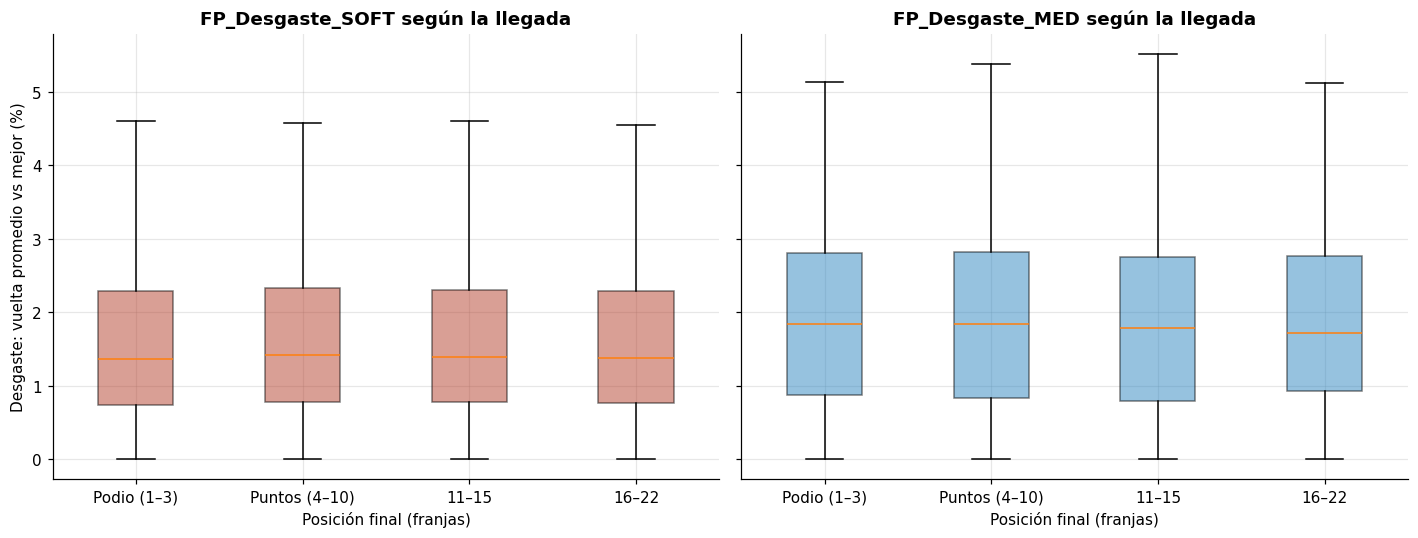

In [ ]:
en_puntos = df[target] <= 10
filas = []
for comp in ["SOFT", "MED"]:
    col = f"FP_Desgaste_{comp}"
    sep, n_a, n_b = separacion(df[col], en_puntos)
    dy = df[[col, target]].dropna()
    filas.append({
        "Columna": col,
        "Media en los puntos (%)": df.loc[en_puntos, col].mean(),
        "Media del resto (%)": df.loc[~en_puntos, col].mean(),
        "n (puntos / resto)": f"{n_a} / {n_b}",
        "Separación estandarizada": sep,
        "Zona": semaforo(sep, "separacion"),
        "Spearman con resultado": dy[col].corr(dy[target], method="spearman"),
    })
mostrar(pd.DataFrame(filas).set_index("Columna"), "H7 · Desgaste de los que terminan en los puntos contra el resto",
        decimales=3, zonas=["Zona"])

FRANJAS_LLEGADA = [0, 3, 10, 15, 22]
NOMBRES_LLEGADA = ["Podio (1–3)", "Puntos (4–10)", "11–15", "16–22"]
franja_llegada = pd.cut(df[target], FRANJAS_LLEGADA, labels=NOMBRES_LLEGADA)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, comp, color in zip(axes, ["SOFT", "MED"], ["#B5402C", "#2E86C1"]):
    col = f"FP_Desgaste_{comp}"
    datos = [df.loc[franja_llegada == f, col].dropna() for f in NOMBRES_LLEGADA]
    caja = ax.boxplot(datos, tick_labels=NOMBRES_LLEGADA, showfliers=False, patch_artist=True)
    for p in caja["boxes"]:
        p.set_facecolor(color)
        p.set_alpha(0.5)
    ax.set_title(f"FP_Desgaste_{comp} según la llegada")
    ax.set_xlabel("Posición final (franjas)")
axes[0].set_ylabel("Desgaste: vuelta promedio vs mejor (%)")
plt.tight_layout()
plt.show()

**4. Qué encontré.** Separación **0,031** (SOFT) y **0,008** (MED) → **rojo**. Las cajas del
gráfico son prácticamente iguales en todas las franjas: la mediana del desgaste está alrededor de
**1,4%** con SOFT y **1,8%** con MED, termine el piloto primero o último. La correlación con el
resultado también es nula (**−0,009** y **−0,007**).

**5. Qué movimiento hice.** Ninguno (rojo).

**6. Qué hago con eso.** **Refutada:** el desgaste **no predice el resultado por sí solo**. Junto
con H6, la decisión queda así: `FP_Desgaste_SOFT` y `FP_Desgaste_MED` entran al modelo **solo
como variables que modifican el peso de las mejores vueltas**, no como predictores directos. Si
el modelo final no puede combinar variables (un lineal sin términos cruzados), no van a aportar
nada y conviene sacarlas.

### Resumen de las hipótesis

In [ ]:
resumen_h = pd.DataFrame([
    ("H1 · La grilla manda", "responder", "asociación", "Spearman 0,625", "verde", "ninguno",
     "confirmada", "Entra Q_GridPosition; sale Q_Position"),
    ("H2 · Una vuelta resume la clasificación", "responder", "asociación",
     "(a) Spearman 0,585 · (b) tandas 0,95/0,86/0,81, parciales ≤ 0,12", "amarillo / verde",
     "cambiar la escala (a)", "(b) confirmada; (a) moderada",
     "Entra Q_Best (log si el modelo es lineal); salen Q1/Q2/Q3"),
    ("H3 · La velocidad anticipa el resultado", "predecir", "asociación",
     "Spearman −0,303 → parcial −0,081", "amarillo → rojo", "controlar la grilla", "refutada",
     "Sale toda la telemetría (18 columnas)"),
    ("H4 · El contexto no aporta", "predecir", "asociación", "Spearman entre −0,154 y 0,175", "rojo",
     "ninguno", "confirmada", "Salen Year, RoundNumber, Races_Before, FinishRate, Avg_Gain"),
    ("H5 · SOFT y MED miden lo mismo", "predecir", "asociación", "Spearman 0,537 (Pearson log 0,512)",
     "amarillo", "cambiar la escala", "inconclusa", "Se quedan las dos (no se probó redundancia)"),
    ("H6 · El desgaste decide qué compuesto importa", "predecir", "comparación (5 grupos)",
     "cambio de ventaja 0,186", "verde", "ninguno", "confirmada",
     "Entran FP_Desgaste_SOFT y FP_Desgaste_MED (del pipeline)"),
    ("H7 · Los de adelante se degradan menos", "predecir", "comparación (2 grupos)",
     "separación 0,031 / 0,008", "rojo", "ninguno", "refutada",
     "El desgaste entra solo como modificador, no como predictor directo"),
], columns=["Hipótesis", "Pregunta", "Plantilla", "Medida", "Zona", "Movimiento", "Resultado", "Decisión"])
resumen_h["Zona final"] = ["verde", "amarillo", "rojo", "rojo", "amarillo", "verde", "rojo"]
mostrar(resumen_h.set_index("Hipótesis"), "Las siete hipótesis de un vistazo", zonas=["Zona final"],
        texto_largo=True)

,Pregunta,Plantilla,Medida,Zona,Movimiento,Resultado,Decisión,Zona final
Hipótesis,,,,,,,,
H1 · La grilla manda,responder,asociación,"Spearman 0,625",verde,ninguno,confirmada,Entra Q_GridPosition; sale Q_Position,verde
H2 · Una vuelta resume la clasificación,responder,asociación,"(a) Spearman 0,585 · (b) tandas 0,95/0,86/0,81, parciales ≤ 0,12",amarillo / verde,cambiar la escala (a),(b) confirmada; (a) moderada,Entra Q_Best (log si el modelo es lineal); salen Q1/Q2/Q3,amarillo
H3 · La velocidad anticipa el resultado,predecir,asociación,"Spearman −0,303 → parcial −0,081",amarillo → rojo,controlar la grilla,refutada,Sale toda la telemetría (18 columnas),rojo
H4 · El contexto no aporta,predecir,asociación,"Spearman entre −0,154 y 0,175",rojo,ninguno,confirmada,"Salen Year, RoundNumber, Races_Before, FinishRate, Avg_Gain",rojo
H5 · SOFT y MED miden lo mismo,predecir,asociación,"Spearman 0,537 (Pearson log 0,512)",amarillo,cambiar la escala,inconclusa,Se quedan las dos (no se probó redundancia),amarillo
H6 · El desgaste decide qué compuesto importa,predecir,comparación (5 grupos),"cambio de ventaja 0,186",verde,ninguno,confirmada,Entran FP_Desgaste_SOFT y FP_Desgaste_MED (del pipeline),verde
H7 · Los de adelante se degradan menos,predecir,comparación (2 grupos),"separación 0,031 / 0,008",rojo,ninguno,refutada,"El desgaste entra solo como modificador, no como predictor directo",rojo


**Cierre de las hipótesis.** Cuatro confirmadas (H1, H2 en su parte b, H4 y H6), dos refutadas
(H3 y H7) y una inconclusa (H5). Hay dos preguntas de responder (H1 y H2) y cinco de predecir, y
dos plantillas: asociación (H1 a H5) y comparación (H6 y H7). Tres dieron amarillo y cada una
tuvo su movimiento, elegido mirando el gráfico: en H2 y H5 la nube aplastada contra el 0 pidió
cambiar la escala, y en H3 la relación de la velocidad con la grilla pidió controlarla.

Ninguna se contestó solo con un gráfico. Los gráficos explicaron el número y marcaron el
movimiento siguiente. El caso más claro es H3: la velocidad parecía servir, y fue el gráfico
contra la grilla el que mostró que había que descontarla.

Lo que dejan H5, H6 y H7 juntas: SOFT y MED no son la misma medida (H5), el desgaste cambia cuál
de las dos pesa más (H6), pero el desgaste solo no dice nada del resultado (H7). Por eso las dos
columnas de desgaste entran, pero con un rol distinto al de las demás.

## Sección 6: Selección final de variables

Con las hipótesis resueltas, la lista se cierra. De las 7 candidatas sale la telemetría (H3) y
quedan seis. H6 suma **dos columnas derivadas de desgaste** que tiene que exportar el pipeline:
`FP_Desgaste_SOFT` y `FP_Desgaste_MED`. En total son **8 columnas** (6 del dataset + 2 derivadas).

In [ ]:
FINALES = {
    "Q_GridPosition": ("Base", "H1 confirmada: Spearman 0,625, explica cerca del 39% del orden de llegada."),
    "Q_Best_seconds_DBT_%": ("Base", "H2: resume las tres tandas (parciales en rojo). Relación moderada con el resultado (0,585); log(1 + x) si el modelo es lineal."),
    "DriverPoints_Before_DBT_%": ("Base", "Resume el bloque de campeonato (0,906 a 0,995 con las otras columnas)."),
    "FP_LapTime_min_SOFT_DBT_%": ("Base", "Mejor relación con el resultado de las prácticas (0,488) y mejor cobertura (82,0%)."),
    "FP_LapTime_min_MED_DBT_%": ("Base", "H5 inconclusa: no se probó que repita a SOFT. H6: pesa más cuando MED se degrada más."),
    "FP_LapTime_min_HARD_DBT_%": ("Base", "Única medida con compuesto duro (0,335 con el resultado)."),
    "FP_Desgaste_SOFT": ("Modificadora", "H6 confirmada: cambia el peso de SOFT. H7: sola no predice (separación 0,031)."),
    "FP_Desgaste_MED": ("Modificadora", "H6 confirmada: cambia el peso de MED. H7: sola no predice (separación 0,008)."),
}
tabla_final_sel = pd.DataFrame([
    {"Variable": c, "Rol": rol, "Cobertura %": df[c].notna().mean() * 100, "Por qué se queda": m}
    for c, (rol, m) in FINALES.items()
]).set_index("Variable")
mostrar(tabla_final_sel, f"Columnas finales: {len(tabla_final_sel)}", decimales=1, texto_largo=True,
        gradiente=["Cobertura %"])

,Rol,Cobertura %,Por qué se queda
Variable,,,
Q_GridPosition,Base,"98,8","H1 confirmada: Spearman 0,625, explica cerca del 39% del orden de llegada."
Q_Best_seconds_DBT_%,Base,"98,8","H2: resume las tres tandas (parciales en rojo). Relación moderada con el resultado (0,585); log(1 + x) si el modelo es lineal."
DriverPoints_Before_DBT_%,Base,"95,1","Resume el bloque de campeonato (0,906 a 0,995 con las otras columnas)."
FP_LapTime_min_SOFT_DBT_%,Base,"81,9","Mejor relación con el resultado de las prácticas (0,488) y mejor cobertura (82,0%)."
FP_LapTime_min_MED_DBT_%,Base,"73,4",H5 inconclusa: no se probó que repita a SOFT. H6: pesa más cuando MED se degrada más.
FP_LapTime_min_HARD_DBT_%,Base,"46,0","Única medida con compuesto duro (0,335 con el resultado)."
FP_Desgaste_SOFT,Modificadora,"81,9","H6 confirmada: cambia el peso de SOFT. H7: sola no predice (separación 0,031)."
FP_Desgaste_MED,Modificadora,"73,4","H6 confirmada: cambia el peso de MED. H7: sola no predice (separación 0,008)."


**Lectura:** quedan **8 columnas** (6 del dataset + 2 derivadas), con cobertura entre **46,1%** y
**98,8%**. De la lista corta solo sale `FP_Speed_fastlap_DBT_%`: descontada la grilla, su relación
con el resultado es **−0,081** (H3). Las dos de desgaste tienen un rol distinto: no predicen solas
(H7), pero cambian cuánto pesan las mejores vueltas (H6).

Los demás descartes se resolvieron antes: falta de datos (INTER 10,4% y WET 4,5%), la regla ABS
vs DBT (todas las absolutas), la redundancia (campeonato, tandas de clasificación y vueltas
promedio) y las hipótesis H3 y H4.

**Chequeo de las vueltas promedio.** Falta confirmar que las vueltas promedio (`mean`) no agregan
nada contra el objetivo. Si agregaran, habría que conservarlas además de las mejores vueltas.

In [ ]:
BASE_FINAL = ["Q_GridPosition", "DriverPoints_Before_DBT_%", "FP_LapTime_min_SOFT_DBT_%",
              "FP_LapTime_min_MED_DBT_%", "FP_LapTime_min_HARD_DBT_%"]
filas = []
for comp in ["SOFT", "MED", "HARD"]:
    cmin, cmean = f"FP_LapTime_min_{comp}_DBT_%", f"FP_LapTime_mean_{comp}_DBT_%"
    d = df[[cmin, cmean, target]].dropna()
    p_min, _ = parcial(df, cmean, target, [cmin])
    p_lista, _ = parcial(df, cmean, target, BASE_FINAL)
    filas.append({
        "Compuesto": comp, "n": len(d),
        "ρ mejor vuelta": d[cmin].corr(d[target], method="spearman"),
        "ρ vuelta promedio": d[cmean].corr(d[target], method="spearman"),
        "Parcial promedio, sin la mejor vuelta": p_min,
        "Parcial promedio, sin la lista final": p_lista,
        "Zona": semaforo(p_min, "correlacion"),
    })
mostrar(pd.DataFrame(filas).set_index("Compuesto"), "¿La vuelta promedio agrega algo sobre la mejor?",
        decimales=3, zonas=["Zona"])

,n,ρ mejor vuelta,ρ vuelta promedio,"Parcial promedio, sin la mejor vuelta","Parcial promedio, sin la lista final",Zona
Compuesto,,,,,,
SOFT,3035,"0,490","0,331","0,020","-0,012",rojo
MED,2718,"0,416","0,313","0,039","0,013",rojo
HARD,1703,"0,339","0,288","0,038","0,018",rojo


**Lectura:** la vuelta promedio se relaciona con el resultado **menos** que la mejor vuelta (SOFT
**0,331 contra 0,488**; MED **0,314 contra 0,415**; HARD **0,283 contra 0,335**). Descontando la
mejor vuelta no agrega casi nada (**+0,021 / +0,041 / +0,035**, rojo), y descontando toda la lista
final, nada (**−0,013 / +0,012 / +0,015**). Por eso el ritmo se mide con la mejor vuelta y no con
la promedio. La promedio solo se usa para calcular el desgaste.

## Sección 7: Tabla final de selección de variables

La tabla junta las 59 columnas **por regla**: cada fila reúne las que comparten la misma decisión
y el mismo motivo. Así se lee de un vistazo qué entra, qué sale y por qué, sin repetir 59 filas.
Todos los números salen de las secciones anteriores.

In [ ]:
GRUPOS = [
    {
        "Grupo": "Columnas finales",
        "Columnas": ["Q_GridPosition", "Q_Best_seconds_DBT_%", "DriverPoints_Before_DBT_%",
                     "FP_LapTime_min_SOFT_DBT_%", "FP_LapTime_min_MED_DBT_%", "FP_LapTime_min_HARD_DBT_%"],
        "Qué miden": "Largada; ritmo de clasificación; distancia al líder del campeonato; ritmo de prácticas con blando, medio y duro",
        "Evidencia": "H1 (0,625, verde); H2 (Q_Best resume las tandas); relación con el resultado en la Sección 3 (Q_Best 0,585; FP 0,488/0,415/0,335); no repiten a otra columna",
        "Decisión": "Se quedan",
    },
    {
        "Grupo": "Clasificación redundante",
        "Columnas": ["Q_Position", "Q1_seconds_DBT_%", "Q2_seconds_DBT_%", "Q3_seconds_DBT_%"],
        "Qué miden": "Posición de clasificación y tiempos de Q1/Q2/Q3 (DBT)",
        "Evidencia": "Q_Position repite a la grilla (0,961); Q1/Q2/Q3 repiten a Q_Best (0,81/0,86/0,95) y no agregan (H2)",
        "Decisión": "Se eliminan",
    },
    {
        "Grupo": "Clasificación absoluta",
        "Columnas": ["Q1_seconds_ABS", "Q2_seconds_ABS", "Q3_seconds_ABS", "Q_Best_seconds_ABS"],
        "Qué miden": "Los mismos tiempos de clasificación, en segundos",
        "Evidencia": "Regla ABS vs DBT: con el resultado, las ABS no pasan de 0,055; las DBT llegan a 0,585",
        "Decisión": "Se eliminan",
    },
    {
        "Grupo": "Campeonato redundante",
        "Columnas": ["DriverPosition_Before", "DriverPoints_Before", "DriverPoints_Rate_Before",
                     "TeamPosition_Before", "TeamPoints_Before"],
        "Qué miden": "Posición y puntos del piloto y del equipo antes de la fecha",
        "Evidencia": "Repiten a DriverPoints_Before_DBT_%: −0,995 (Rate), 0,966 (posición), 0,906/0,892 (equipo), −0,926/0,954 (puntos)",
        "Decisión": "Se eliminan",
    },
    {
        "Grupo": "Prácticas con pocos datos",
        "Columnas": ["FP_LapTime_min_INTER_ABS", "FP_LapTime_min_INTER_DBT_%",
                     "FP_LapTime_min_WET_ABS", "FP_LapTime_min_WET_DBT_%"],
        "Qué miden": "Mejor vuelta con intermedios y con lluvia",
        "Evidencia": "Cobertura 10,4% (INTER) y 4,5% (WET)",
        "Decisión": "Se eliminan",
    },
    {
        "Grupo": "Prácticas: vueltas promedio (DBT)",
        "Columnas": ["FP_LapTime_mean_SOFT_DBT_%", "FP_LapTime_mean_MED_DBT_%", "FP_LapTime_mean_HARD_DBT_%"],
        "Qué miden": "Vuelta promedio con blando, medio y duro",
        "Evidencia": "Siguen a la mejor vuelta (Pearson 0,87 a 0,93) y no agregan sobre ella (+0,021/+0,041/+0,035, rojo)",
        "Decisión": "Se eliminan",
    },
    {
        "Grupo": "Prácticas: tiempos absolutos",
        "Columnas": ["FP_LapTime_min_SOFT_ABS", "FP_LapTime_mean_SOFT_ABS",
                     "FP_LapTime_min_MED_ABS", "FP_LapTime_mean_MED_ABS",
                     "FP_LapTime_min_HARD_ABS", "FP_LapTime_mean_HARD_ABS"],
        "Qué miden": "Mejor vuelta y vuelta promedio, en segundos",
        "Evidencia": "Regla ABS vs DBT. El desgaste se calcula con ellas, pero lo hace el pipeline",
        "Decisión": "Se eliminan",
    },
    {
        "Grupo": "Telemetría",
        "Columnas": FAMILIAS["Telemetría"],
        "Qué miden": "Acelerador, velocidad, RPM y freno, en ABS y DBT",
        "Evidencia": "H3 refutada: −0,303 con el resultado, pero −0,081 descontando la grilla; el bloque se repite (0,994/0,984)",
        "Decisión": "Se eliminan",
    },
    {
        "Grupo": "Contexto (H4)",
        "Columnas": ["Year", "RoundNumber", "Races_Before", "FinishRate_Before", "Avg_Position_Gain_Before"],
        "Qué miden": "Temporada, fecha, experiencia y regularidad",
        "Evidencia": "H4 confirmada: todas en rojo (entre −0,154 y 0,175)",
        "Decisión": "Se eliminan (Year y RoundNumber quedan solo para separar entrenamiento y prueba)",
    },
    {
        "Grupo": "Identificadores",
        "Columnas": ["DriverId", "TeamId", "DriverNumber"],
        "Qué miden": "Piloto, escudería y dorsal",
        "Evidencia": "η² 0,324 y 0,279, pero cambian con la era (Red Bull 3,57 → 9,12); el dorsal, ρ = 0,005",
        "Decisión": "Se eliminan",
    },
    {
        "Grupo": "Objetivo",
        "Columnas": [target],
        "Qué miden": "Posición final de carrera",
        "Evidencia": "—",
        "Decisión": "Es el objetivo",
    },
]

tabla_grupos = pd.DataFrame(GRUPOS)
tabla_grupos["n"] = tabla_grupos["Columnas"].apply(len)
tabla_grupos["Columnas"] = tabla_grupos["Columnas"].apply(", ".join)
total = int(tabla_grupos["n"].sum())
quedan = int(tabla_grupos.loc[tabla_grupos.Decisión == "Se quedan", "n"].sum())
objetivo = int(tabla_grupos.loc[tabla_grupos.Decisión == "Es el objetivo", "n"].sum())
eliminan = total - quedan - objetivo

mostrar(pd.DataFrame({"Columnas": {"Evaluadas": total, "Se quedan": quedan, "Se eliminan": eliminan,
                                   "Objetivo": objetivo, "Derivadas nuevas (pipeline)": 2}}),
        "Balance de la selección")
mostrar(tabla_grupos.set_index("Grupo")[["n", "Decisión", "Qué miden", "Evidencia", "Columnas"]],
        "Las 59 columnas del dataset, agrupadas por decisión", texto_largo=True)

,Columnas
Evaluadas,59
Se quedan,6
Se eliminan,52
Objetivo,1
Derivadas nuevas (pipeline),2


,n,Decisión,Qué miden,Evidencia,Columnas
Grupo,,,,,
Columnas finales,6,Se quedan,"Largada; ritmo de clasificación; distancia al líder del campeonato; ritmo de prácticas con blando, medio y duro","H1 (0,625, verde); H2 (Q_Best resume las tandas); relación con el resultado en la Sección 3 (Q_Best 0,585; FP 0,488/0,415/0,335); no repiten a otra columna","Q_GridPosition, Q_Best_seconds_DBT_%, DriverPoints_Before_DBT_%, FP_LapTime_min_SOFT_DBT_%, FP_LapTime_min_MED_DBT_%, FP_LapTime_min_HARD_DBT_%"
Clasificación redundante,4,Se eliminan,Posición de clasificación y tiempos de Q1/Q2/Q3 (DBT),"Q_Position repite a la grilla (0,961); Q1/Q2/Q3 repiten a Q_Best (0,81/0,86/0,95) y no agregan (H2)","Q_Position, Q1_seconds_DBT_%, Q2_seconds_DBT_%, Q3_seconds_DBT_%"
Clasificación absoluta,4,Se eliminan,"Los mismos tiempos de clasificación, en segundos","Regla ABS vs DBT: con el resultado, las ABS no pasan de 0,055; las DBT llegan a 0,585","Q1_seconds_ABS, Q2_seconds_ABS, Q3_seconds_ABS, Q_Best_seconds_ABS"
Campeonato redundante,5,Se eliminan,Posición y puntos del piloto y del equipo antes de la fecha,"Repiten a DriverPoints_Before_DBT_%: −0,995 (Rate), 0,966 (posición), 0,906/0,892 (equipo), −0,926/0,954 (puntos)","DriverPosition_Before, DriverPoints_Before, DriverPoints_Rate_Before, TeamPosition_Before, TeamPoints_Before"
Prácticas con pocos datos,4,Se eliminan,Mejor vuelta con intermedios y con lluvia,"Cobertura 10,4% (INTER) y 4,5% (WET)","FP_LapTime_min_INTER_ABS, FP_LapTime_min_INTER_DBT_%, FP_LapTime_min_WET_ABS, FP_LapTime_min_WET_DBT_%"
Prácticas: vueltas promedio (DBT),3,Se eliminan,"Vuelta promedio con blando, medio y duro","Siguen a la mejor vuelta (Pearson 0,87 a 0,93) y no agregan sobre ella (+0,021/+0,041/+0,035, rojo)","FP_LapTime_mean_SOFT_DBT_%, FP_LapTime_mean_MED_DBT_%, FP_LapTime_mean_HARD_DBT_%"
Prácticas: tiempos absolutos,6,Se eliminan,"Mejor vuelta y vuelta promedio, en segundos","Regla ABS vs DBT. El desgaste se calcula con ellas, pero lo hace el pipeline","FP_LapTime_min_SOFT_ABS, FP_LapTime_mean_SOFT_ABS, FP_LapTime_min_MED_ABS, FP_LapTime_mean_MED_ABS, FP_LapTime_min_HARD_ABS, FP_LapTime_mean_HARD_ABS"
Telemetría,18,Se eliminan,"Acelerador, velocidad, RPM y freno, en ABS y DBT","H3 refutada: −0,303 con el resultado, pero −0,081 descontando la grilla; el bloque se repite (0,994/0,984)","FP_Throttle_fastlap_ABS, FP_Speed_fastlap_ABS, FP_Speed_max_ABS, FP_RPM_fastlap_ABS, FP_Brake_fastlap_ABS, FP_Throttle_fastlap_DBT_%, FP_Speed_fastlap_DBT_%, FP_Speed_max_DBT_%, FP_RPM_fastlap_DBT_%, FP_Brake_fastlap_DBT_%, FP_Throttle_mean_MED_ABS, FP_Speed_mean_MED_ABS, FP_RPM_mean_MED_ABS, FP_Brake_mean_MED_ABS, FP_Throttle_mean_MED_DBT_%, FP_Speed_mean_MED_DBT_%, FP_RPM_mean_MED_DBT_%, FP_Brake_mean_MED_DBT_%"
Contexto (H4),5,Se eliminan (Year y RoundNumber quedan solo para separar entrenamiento y prueba),"Temporada, fecha, experiencia y regularidad","H4 confirmada: todas en rojo (entre −0,154 y 0,175)","Year, RoundNumber, Races_Before, FinishRate_Before, Avg_Position_Gain_Before"


**Lectura:** del dataset quedan **6 columnas + el objetivo**. Los **52 descartes** se reparten así:
redundancia (9: Q_Position, Q1/Q2/Q3 y cinco de campeonato), regla ABS (10), vueltas promedio (3),
pocos datos (4), contexto (5), identificadores (3) y el bloque de telemetría (18). A eso se suman
las **2 columnas de desgaste** que exporta el pipeline, así que el modelo recibe **8 columnas**.

## Sección 8: Cambios documentados del pipeline

### 8.1 Cambios ya hechos (versión CSV → versión Parquet actual)

| Cambio | Detalle |
|---|---|
| Prácticas unificadas | FP1, FP2 y FP3 pasaron a una sola familia `FP_` |
| Nombres estandarizados | `QualyPosition/QualyQ1..Q3` → `Q_Position`, `Q1..Q3_seconds_*`; los sufijos `_ABS` / `_DBT_%` reemplazan a `_diff_to_best` |
| Fuga de datos eliminada | Se quitaron `Race_ClassifiedPosition`, `Race_Status`, `Race_Points` y `Race_Laps`; queda `RACE_Position` como único objetivo |
| Columnas relativas nuevas | `DriverPoints_Before_DBT_%`, `DriverPoints_Rate_Before`, `Races_Before`, `FinishRate_Before`, `Avg_Position_Gain_Before` |
| Telemetría unificada | Se agregaron `_fastlap` y `_mean_MED`, y `FP_LapTime_mean_HARD_*` |
| Formato de salida | Parquet + diccionario `columnas.md` |

### 8.2 Cambios pendientes (surgen de este EDA)

| Prioridad | Cambio | Por qué |
|---|---|---|
| Alta | **Sacar duplicados** por `(Year, RoundNumber, DriverId)` | 10 filas repetidas en 2023-R11 y 2025-R16 |
| Alta | Pasar a nulo los ceros que no son datos: `Q_GridPosition = 0`, posiciones de campeonato = 0 en la primera fecha y telemetría = 0 | 45 + 182 + 153 filas |
| Alta | **Calcular y exportar** `FP_Desgaste_{SOFT,MED} = (mean_ABS − min_ABS) / min_ABS × 100` | H6: el desgaste cambia el peso de cada mejor vuelta |
| Alta | **Dejar de generar la telemetría** (al menos las `_DBT_%`, que se dividen por lecturas mínimas basura) | H3 refutada; DBT de hasta 3.583% por mínimos de 6 a 8 km/h |
| Media | Documentar y validar que las `_Before` se calculan antes de la fecha | Chequeo de fuga de la Sección 4 |
| Baja | Exportar solo las columnas que se quedan | De 59 a 6 + 2 de desgaste + objetivo + identificadores |
| Baja | Definir cómo completar `DriverPoints_Before_DBT_%` en la primera fecha | 182 filas (4,9%) sin líder de puntos |

**¿Por qué el desgaste lo tiene que calcular el pipeline y no el notebook a partir de las DBT?**
Porque la mejor vuelta DBT y la vuelta promedio DBT se miden contra **referencias distintas**: la
primera contra la mejor vuelta de la carrera y la segunda contra la mejor vuelta *promedio*. Un
ejemplo lo muestra:

In [ ]:
ej = df[(df.Year == 2019) & (df.RoundNumber == 1) & (df.DriverId == "albon")].iloc[0]
mostrar(pd.DataFrame({"Referencia de la carrera (s)": {
    "Contra la que se mide la mejor vuelta SOFT DBT":
        ej["FP_LapTime_min_SOFT_ABS"] / (1 + ej["FP_LapTime_min_SOFT_DBT_%"] / 100),
    "Contra la que se mide la vuelta promedio SOFT DBT":
        ej["FP_LapTime_mean_SOFT_ABS"] / (1 + ej["FP_LapTime_mean_SOFT_DBT_%"] / 100),
}}), "Ejemplo: 2019, ronda 1, compuesto SOFT")

,Referencia de la carrera (s)
Contra la que se mide la mejor vuelta SOFT DBT,"82,29"
Contra la que se mide la vuelta promedio SOFT DBT,"83,24"


Las dos referencias no coinciden (**82,29 s** contra **83,24 s**), así que restar las dos DBT no
da el desgaste. Hace falta el par en segundos, que el pipeline tiene.

> El análisis temporal (tendencias por año o por ronda) queda fuera de alcance, según lo acordado.

# Cierre

**Recorrido:** dataset → inspección inicial → univariado por familia → bivariado selectivo →
lista corta → calidad → 7 hipótesis → selección final → tabla de 59 columnas → cambios del
pipeline.

**Qué columnas le damos al modelo:** la grilla, Q_Best, la distancia en puntos al líder y las
mejores vueltas de prácticas con SOFT, MED y HARD (6 del dataset), más las dos columnas de
desgaste como modificadoras (2 derivadas). **Qué descartamos:** la telemetría completa (no agrega
sobre la grilla, H3), las variables de contexto (H4), los identificadores (cambian con la era),
las versiones ABS y todo lo que repite a otra columna. **Qué quedó sin resolver:** si SOFT y MED
son redundantes (H5, inconclusa); qué tan grande es el efecto del desgaste (su medida está cerca
del corte de verde); y cuánto agregan Q_Best y las mejores vueltas por encima de la grilla cuando
se usan todas juntas. Eso último lo va a contestar el modelo.

**Los números que resumen el trabajo:**

1. **0,625:** Spearman entre la grilla y la posición final. Es la base del modelo (H1).
2. **0,95 / 0,86 / 0,81:** cuánto se parecen Q3, Q2 y Q1 a Q_Best. Una sola vuelta de
   clasificación alcanza (H2).
3. **−0,081:** relación de la velocidad con el resultado una vez descontada la grilla. Por eso se
   va la telemetría (H3), y no se veía mirando solo la correlación directa.
4. **0,186 contra 0,03:** el desgaste cambia cuánto pesa cada compuesto (H6), pero solo no separa
   a los de adelante de los de atrás (H7).
5. **1,56:** posiciones que se mueve un equipo de un año al otro. Por eso `TeamId` y `DriverId`
   quedan afuera.

El número decide y el gráfico explica: ese es todo el método.